<a href="https://colab.research.google.com/github/2010626140/pIC50-calculation/blob/main/Newly_Developed_ML_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==========================================================
# STEP 1.1 : Install Required Python Libraries
# ==========================================================
#
# Purpose:
# Install all Python libraries required for this project.
#
# Required only once.
#
# ==========================================================

!pip install -q chembl_webresource_client
!pip install -q rdkit
!pip install -q pandas
!pip install -q numpy
!pip install -q matplotlib
!pip install -q seaborn
!pip install -q scikit-learn
!pip install -q openpyxl
!pip install -q tqdm

In [ ]:
# ==========================================================
# STEP 1.2 : Import Required Libraries
# ==========================================================

# Data manipulation
import pandas as pd
import numpy as np

# ChEMBL API
from chembl_webresource_client.new_client import new_client

# RDKit
from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem import SaltRemover

# Progress bar
from tqdm import tqdm

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# ==========================================================
# STEP 1.3 : Check Library Versions
# ==========================================================

import sklearn
import rdkit

print("="*60)
print("Library Versions")
print("="*60)

print(f"Pandas               : {pd.__version__}")
print(f"NumPy                : {np.__version__}")
print(f"Scikit-learn         : {sklearn.__version__}")
print(f"RDKit                : {rdkit.__version__}")

print("="*60)
print("Environment is Ready!")
print("="*60)

Library Versions
Pandas               : 2.2.2
NumPy                : 2.0.2
Scikit-learn         : 1.6.1
RDKit                : 2026.03.4
Environment is Ready!


In [ ]:
# ==========================================================
# STEP 1.4 : Set Random Seed
# ==========================================================

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

print(f"Random Seed = {RANDOM_STATE}")

Random Seed = 42


In [ ]:
# ==========================================================
# STEP 1.5 : Create Project Folder Structure
# ==========================================================

import os

folders = [

    "Data",

    "Data/Raw",

    "Data/Clean",

    "Descriptors",

    "Models",

    "Results",

    "Figures",

    "Predictions"

]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [ ]:
# ==========================================================
# STEP 1.6 : Project Information
# ==========================================================

PROJECT_NAME = "HER2 pIC50 Prediction using Machine Learning"

TARGET_NAME = "HER2"

TARGET_GENE = "ERBB2"

ACTIVITY_TYPE = "IC50"

STANDARD_UNIT = "nM"

print("="*60)
print(PROJECT_NAME)
print("="*60)

print(f"Target           : {TARGET_NAME}")
print(f"Gene             : {TARGET_GENE}")
print(f"Activity         : {ACTIVITY_TYPE}")
print(f"Unit             : {STANDARD_UNIT}")

print("="*60)

HER2 pIC50 Prediction using Machine Learning
Target           : HER2
Gene             : ERBB2
Activity         : IC50
Unit             : nM


In [ ]:
# ==========================================================
# STEP 2.1 : Search HER2 Targets in ChEMBL
# ==========================================================
#
# Purpose:
# Search ChEMBL for HER2 / ERBB2 related targets.
#
# Output:
# List of all HER2-related targets available in ChEMBL.
# ==========================================================

target = new_client.target

search_results = target.search("HER2")

print("="*80)
print(f"Number of Targets Found : {len(search_results)}")
print("="*80)

Number of Targets Found : 6


In [ ]:
# ==========================================================
# STEP 2.2 : Display HER2 Target Information
# ==========================================================

target_list = []

for t in search_results:

    target_list.append({

        "Target Name": t.get("pref_name"),

        "Target Type": t.get("target_type"),

        "Organism": t.get("organism"),

        "ChEMBL ID": t.get("target_chembl_id")

    })

target_df = pd.DataFrame(target_list)

target_df

,Target Name,Target Type,Organism,ChEMBL ID
0,FASN/HER2,PROTEIN COMPLEX,Homo sapiens,CHEMBL4106134
1,Receptor tyrosine-protein kinase erbB-2,SINGLE PROTEIN,Homo sapiens,CHEMBL1824
2,von Hippel-Lindau disease tumor suppressor/Rec...,PROTEIN-PROTEIN INTERACTION,Homo sapiens,CHEMBL5465227
3,Epidermal growth factor receptor and ErbB2 (HE...,PROTEIN FAMILY,Homo sapiens,CHEMBL2111431
4,ErbB-2/ErbB-3 heterodimer,PROTEIN COMPLEX,Homo sapiens,CHEMBL4630723
5,Epidermal growth factor receptor,PROTEIN FAMILY,Homo sapiens,CHEMBL2363049


In [ ]:
# ==========================================================
# STEP 2.3 : Filter Human Targets
# ==========================================================

human_targets = target_df[
    target_df["Organism"] == "Homo sapiens"
]

human_targets.reset_index(drop=True, inplace=True)

human_targets

,Target Name,Target Type,Organism,ChEMBL ID
0,FASN/HER2,PROTEIN COMPLEX,Homo sapiens,CHEMBL4106134
1,Receptor tyrosine-protein kinase erbB-2,SINGLE PROTEIN,Homo sapiens,CHEMBL1824
2,von Hippel-Lindau disease tumor suppressor/Rec...,PROTEIN-PROTEIN INTERACTION,Homo sapiens,CHEMBL5465227
3,Epidermal growth factor receptor and ErbB2 (HE...,PROTEIN FAMILY,Homo sapiens,CHEMBL2111431
4,ErbB-2/ErbB-3 heterodimer,PROTEIN COMPLEX,Homo sapiens,CHEMBL4630723
5,Epidermal growth factor receptor,PROTEIN FAMILY,Homo sapiens,CHEMBL2363049


In [ ]:
# ==========================================================
# STEP 2.4 : Keep Only Single Protein Targets
# ==========================================================

single_protein = human_targets[
    human_targets["Target Type"] == "SINGLE PROTEIN"
]

single_protein.reset_index(drop=True, inplace=True)

single_protein

,Target Name,Target Type,Organism,ChEMBL ID
0,Receptor tyrosine-protein kinase erbB-2,SINGLE PROTEIN,Homo sapiens,CHEMBL1824


In [ ]:
# ==========================================================
# STEP 2.5 : Select HER2 Target
# ==========================================================

TARGET_CHEMBL_ID = "CHEMBL1824"

print("="*60)
print("Selected Target")
print("="*60)

print(f"Target Name : HER2 (ERBB2)")
print(f"ChEMBL ID   : {TARGET_CHEMBL_ID}")

Selected Target
Target Name : HER2 (ERBB2)
ChEMBL ID   : CHEMBL1824


In [ ]:
# ==========================================================
# STEP 2.6 : Verify Selected Target
# ==========================================================

target_info = target.get(TARGET_CHEMBL_ID)

print("="*60)
print("Target Verification")
print("="*60)

print(f"Target Name      : {target_info['pref_name']}")
print(f"Target Type      : {target_info['target_type']}")
print(f"Organism         : {target_info['organism']}")
print(f"ChEMBL ID        : {target_info['target_chembl_id']}")

Target Verification
Target Name      : Receptor tyrosine-protein kinase erbB-2
Target Type      : SINGLE PROTEIN
Organism         : Homo sapiens
ChEMBL ID        : CHEMBL1824


In [ ]:
# ==========================================================
# STEP 3.1 : Connect to ChEMBL Activity Database
# ==========================================================
#
# Purpose:
# Connect to the ChEMBL activity endpoint.
#
# ==========================================================

activity = new_client.activity

print("Successfully connected to ChEMBL Activity Database.")

Successfully connected to ChEMBL Activity Database.


In [ ]:
# ==========================================================
# STEP 3.2 : Download All HER2 Bioactivity Data
# ==========================================================
#
# Purpose:
# Download every reported activity associated with HER2.
#
# ==========================================================

raw_activity = activity.filter(
    target_chembl_id=TARGET_CHEMBL_ID
)

raw_activity = pd.DataFrame(raw_activity)

print("="*60)
print("Raw HER2 Activity Dataset")
print("="*60)

print(f"Number of bioactivity records : {len(raw_activity):,}")
print(f"Number of columns            : {raw_activity.shape[1]}")

Raw HER2 Activity Dataset
Number of bioactivity records : 11,069
Number of columns            : 47


In [ ]:
# ==========================================================
# STEP 3.3 : Display Dataset Information
# ==========================================================

print("="*60)
print("Dataset Shape")
print("="*60)

print(raw_activity.shape)

print("\n")

print("="*60)
print("Column Names")
print("="*60)

for i, column in enumerate(raw_activity.columns, start=1):
    print(f"{i:02d}. {column}")

Dataset Shape
(11069, 47)


Column Names
01. action_type
02. activity_comment
03. activity_id
04. activity_properties
05. assay_chembl_id
06. assay_description
07. assay_type
08. assay_variant_accession
09. assay_variant_mutation
10. bao_endpoint
11. bao_format
12. bao_label
13. canonical_smiles
14. data_validity_comment
15. data_validity_description
16. document_chembl_id
17. document_journal
18. document_year
19. ligand_efficiency
20. modality
21. molecule_chembl_id
22. molecule_pref_name
23. parent_molecule_chembl_id
24. pchembl_value
25. potential_duplicate
26. qudt_units
27. record_id
28. relation
29. src_id
30. standard_flag
31. standard_relation
32. standard_text_value
33. standard_type
34. standard_units
35. standard_upper_value
36. standard_value
37. target_chembl_id
38. target_organism
39. target_pref_name
40. target_tax_id
41. text_value
42. toid
43. type
44. units
45. uo_units
46. upper_value
47. value


In [ ]:
# ==========================================================
# STEP 3.4 : Preview Raw Dataset
# ==========================================================

raw_activity.head()

,action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,...,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
0,None,None,32264,[],CHEMBL845865,Inhibition of autophosphorylation of human Her...,F,None,None,BAO_0000190,...,Homo sapiens,Receptor tyrosine-protein kinase erbB-2,9606,None,None,IC50,uM,UO_0000065,None,0.3
1,None,None,32266,[],CHEMBL615491,Inhibition of ligand induced proliferation in ...,F,None,None,BAO_0000190,...,Homo sapiens,Receptor tyrosine-protein kinase erbB-2,9606,None,None,IC50,uM,UO_0000065,None,2.5
2,None,None,32271,[],CHEMBL683802,Inhibition of autophosphorylation of human Her...,F,None,None,BAO_0000190,...,Homo sapiens,Receptor tyrosine-protein kinase erbB-2,9606,None,None,IC50,uM,UO_0000065,None,0.4
3,None,None,32273,[],CHEMBL615491,Inhibition of ligand induced proliferation in ...,F,None,None,BAO_0000190,...,Homo sapiens,Receptor tyrosine-protein kinase erbB-2,9606,None,None,IC50,uM,UO_0000065,None,1.21
4,None,None,47937,[],CHEMBL683802,Inhibition of autophosphorylation of human Her...,F,None,None,BAO_0000190,...,Homo sapiens,Receptor tyrosine-protein kinase erbB-2,9606,None,None,IC50,uM,UO_0000065,None,0.1


In [ ]:
# ==========================================================
# STEP 3.5 : Missing Value Summary
# ==========================================================

missing = raw_activity.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print("="*60)
print("Missing Values")
print("="*60)

display(missing)

Missing Values


,0
standard_upper_value,11069
toid,11069
assay_variant_accession,11039
assay_variant_mutation,11033
modality,11006
data_validity_comment,10996
data_validity_description,10996
upper_value,10885
action_type,10445
text_value,9140


In [ ]:
# ==========================================================
# STEP 3.6 : Save Raw HER2 Dataset
# ==========================================================

raw_activity.to_csv(
    "Data/Raw/HER2_ChEMBL_Raw.csv",
    index=False
)

print("Raw dataset saved successfully.")

print("\nLocation:")
print("Data/Raw/HER2_ChEMBL_Raw.csv")

Raw dataset saved successfully.

Location:
Data/Raw/HER2_ChEMBL_Raw.csv


In [ ]:
# ==========================================================
# STEP 3.7 : Dataset Summary
# ==========================================================

print("="*60)
print("HER2 Raw Dataset Summary")
print("="*60)

print(f"Rows    : {raw_activity.shape[0]:,}")
print(f"Columns : {raw_activity.shape[1]}")

print("\nFirst 10 Columns:")

for col in raw_activity.columns[:10]:
    print("-", col)

HER2 Raw Dataset Summary
Rows    : 11,069
Columns : 47

First 10 Columns:
- action_type
- activity_comment
- activity_id
- activity_properties
- assay_chembl_id
- assay_description
- assay_type
- assay_variant_accession
- assay_variant_mutation
- bao_endpoint


In [ ]:
# ==========================================================
# STEP 4.1 : Select Required Columns
# ==========================================================
#
# Purpose:
# Keep only the columns needed for QSAR analysis.
#
# ==========================================================

required_columns = [

    "molecule_chembl_id",
    "canonical_smiles",
    "standard_type",
    "standard_relation",
    "standard_value",
    "standard_units",
    "standard_flag",
    "target_chembl_id",
    "assay_chembl_id",
    "assay_type",
    "assay_description",
    "document_chembl_id",
    "pchembl_value"

]

activity = raw_activity[required_columns].copy()

print("="*60)
print("Dataset after selecting required columns")
print("="*60)

print(activity.shape)

activity.head()

Dataset after selecting required columns
(11069, 13)


,molecule_chembl_id,canonical_smiles,standard_type,standard_relation,standard_value,standard_units,standard_flag,target_chembl_id,assay_chembl_id,assay_type,assay_description,document_chembl_id,pchembl_value
0,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,IC50,=,300.0,nM,1,CHEMBL1824,CHEMBL845865,F,Inhibition of autophosphorylation of human Her...,CHEMBL1134862,6.52
1,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,IC50,=,2500.0,nM,1,CHEMBL1824,CHEMBL615491,F,Inhibition of ligand induced proliferation in ...,CHEMBL1134862,5.60
2,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,IC50,=,400.0,nM,1,CHEMBL1824,CHEMBL683802,F,Inhibition of autophosphorylation of human Her...,CHEMBL1134862,6.40
3,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,IC50,=,1210.0,nM,1,CHEMBL1824,CHEMBL615491,F,Inhibition of ligand induced proliferation in ...,CHEMBL1134862,5.92
4,CHEMBL67057,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,IC50,=,100.0,nM,1,CHEMBL1824,CHEMBL683802,F,Inhibition of autophosphorylation of human Her...,CHEMBL1134862,7.00


In [ ]:
# ==========================================================
# STEP 4.2 : Keep Only IC50 Records
# ==========================================================

print("Records before filtering :", len(activity))

activity = activity[
    activity["standard_type"] == "IC50"
]

print("Records after filtering  :", len(activity))

Records before filtering : 11069
Records after filtering  : 5265


In [ ]:
# ==========================================================
# STEP 4.3 : Keep Only Exact Measurements
# ==========================================================

print("Records before filtering :", len(activity))

activity = activity[
    activity["standard_relation"] == "="
]

print("Records after filtering  :", len(activity))

Records before filtering : 5265
Records after filtering  : 3413


In [ ]:
# ==========================================================
# STEP 4.4 : Keep Only nM Units
# ==========================================================

print("Records before filtering :", len(activity))

activity = activity[
    activity["standard_units"] == "nM"
]

print("Records after filtering  :", len(activity))

Records before filtering : 3413
Records after filtering  : 3384


In [ ]:
# ==========================================================
# STEP 4.5 : Remove Missing SMILES
# ==========================================================

print("Records before filtering :", len(activity))

activity = activity.dropna(
    subset=["canonical_smiles"]
)

print("Records after filtering  :", len(activity))

Records before filtering : 3384
Records after filtering  : 3377


In [ ]:
# ==========================================================
# STEP 4.6 : Remove Missing IC50 Values
# ==========================================================

print("Records before filtering :", len(activity))

activity = activity.dropna(
    subset=["standard_value"]
)

print("Records after filtering  :", len(activity))

Records before filtering : 3377
Records after filtering  : 3377


In [ ]:
# ==========================================================
# STEP 4.7 : Keep Only Standardized Activities
# ==========================================================

print("Records before filtering :", len(activity))

activity = activity[
    activity["standard_flag"] == True
]

print("Records after filtering  :", len(activity))

Records before filtering : 3377
Records after filtering  : 3377


In [ ]:
# ==========================================================
# STEP 4.8 : Reset Index
# ==========================================================

activity.reset_index(
    drop=True,
    inplace=True
)

activity.head()

,molecule_chembl_id,canonical_smiles,standard_type,standard_relation,standard_value,standard_units,standard_flag,target_chembl_id,assay_chembl_id,assay_type,assay_description,document_chembl_id,pchembl_value
0,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,IC50,=,300.0,nM,1,CHEMBL1824,CHEMBL845865,F,Inhibition of autophosphorylation of human Her...,CHEMBL1134862,6.52
1,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,IC50,=,2500.0,nM,1,CHEMBL1824,CHEMBL615491,F,Inhibition of ligand induced proliferation in ...,CHEMBL1134862,5.60
2,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,IC50,=,400.0,nM,1,CHEMBL1824,CHEMBL683802,F,Inhibition of autophosphorylation of human Her...,CHEMBL1134862,6.40
3,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,IC50,=,1210.0,nM,1,CHEMBL1824,CHEMBL615491,F,Inhibition of ligand induced proliferation in ...,CHEMBL1134862,5.92
4,CHEMBL67057,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,IC50,=,100.0,nM,1,CHEMBL1824,CHEMBL683802,F,Inhibition of autophosphorylation of human Her...,CHEMBL1134862,7.00


In [ ]:
# ==========================================================
# STEP 4.9 : Dataset Summary
# ==========================================================

print("="*60)
print("Filtered HER2 Dataset")
print("="*60)

print(f"Rows    : {activity.shape[0]:,}")
print(f"Columns : {activity.shape[1]}")

print("\n")

activity.info()

Filtered HER2 Dataset
Rows    : 3,377
Columns : 13


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3377 entries, 0 to 3376
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   molecule_chembl_id  3377 non-null   object
 1   canonical_smiles    3377 non-null   object
 2   standard_type       3377 non-null   object
 3   standard_relation   3377 non-null   object
 4   standard_value      3377 non-null   object
 5   standard_units      3377 non-null   object
 6   standard_flag       3377 non-null   int64 
 7   target_chembl_id    3377 non-null   object
 8   assay_chembl_id     3377 non-null   object
 9   assay_type          3377 non-null   object
 10  assay_description   3377 non-null   object
 11  document_chembl_id  3377 non-null   object
 12  pchembl_value       3368 non-null   object
dtypes: int64(1), object(12)
memory usage: 343.1+ KB


In [ ]:
# ==========================================================
# STEP 4.10 : Save Filtered Dataset
# ==========================================================

activity.to_csv(
    "Data/Clean/HER2_Filtered.csv",
    index=False
)

print("Filtered dataset saved successfully.")

Filtered dataset saved successfully.


In [ ]:
# ==========================================================
# STEP 5.1 : Convert SMILES to RDKit Molecules
# ==========================================================
#
# Purpose:
# Convert SMILES strings into RDKit molecule objects.
#
# ==========================================================

from rdkit import Chem

activity["ROMol"] = activity["canonical_smiles"].apply(
    lambda x: Chem.MolFromSmiles(x)
)

print("="*60)
print("RDKit Molecule Conversion")
print("="*60)

print(f"Total molecules : {len(activity)}")

print(f"Valid molecules : {activity['ROMol'].notnull().sum()}")

print(f"Invalid molecules : {activity['ROMol'].isnull().sum()}")

RDKit Molecule Conversion
Total molecules : 3377
Valid molecules : 3377
Invalid molecules : 0


In [ ]:
# ==========================================================
# STEP 5.2 : Remove Invalid Molecules
# ==========================================================

print("Before :", len(activity))

activity = activity[
    activity["ROMol"].notnull()
]

print("After  :", len(activity))

Before : 3377
After  : 3377


In [ ]:
# ==========================================================
# STEP 5.3 : Remove Salts
# ==========================================================

from rdkit.Chem import SaltRemover

remover = SaltRemover.SaltRemover()

activity["ROMol"] = activity["ROMol"].apply(
    lambda mol: remover.StripMol(mol)
)

print("Salt removal completed.")

Salt removal completed.


In [ ]:
# ==========================================================
# STEP 5.4 : Generate Canonical SMILES
# ==========================================================

activity["Canonical_SMILES"] = activity["ROMol"].apply(
    lambda mol: Chem.MolToSmiles(
        mol,
        canonical=True
    )
)

activity[
    [
        "canonical_smiles",
        "Canonical_SMILES"
    ]
].head()

,canonical_smiles,Canonical_SMILES
0,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...
1,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...
2,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...
3,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...
4,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...


In [ ]:
# ==========================================================
# STEP 5.5 : Count Duplicate Molecules
# ==========================================================

duplicates = activity.duplicated(
    subset="Canonical_SMILES"
).sum()

print("="*60)
print("Duplicate Molecules")
print("="*60)

print(f"Duplicates found : {duplicates}")

Duplicate Molecules
Duplicates found : 862


In [ ]:
# ==========================================================
# STEP 5.6 : Save Standardized Dataset
# ==========================================================

activity.to_csv(
    "Data/Clean/HER2_Standardized.csv",
    index=False
)

print("Standardized dataset saved successfully.")

Standardized dataset saved successfully.


In [ ]:
# ==========================================================
# STEP 6.1 : Count Replicate Measurements
# ==========================================================
#
# Purpose:
# Determine how many times each molecule has been tested.
#
# ==========================================================

replicate_counts = (
    activity
    .groupby("Canonical_SMILES")
    .size()
    .reset_index(name="Number_of_Assays")
)

print("="*60)
print("Replicate Measurement Summary")
print("="*60)

print(replicate_counts.head())

print("\n")

print(f"Unique molecules : {len(replicate_counts):,}")

Replicate Measurement Summary
                                    Canonical_SMILES  Number_of_Assays
0     Brc1ccc(C2=NN(c3ccccc3)C(c3ccc4ccccc4c3)C2)cc1                 1
1     Brc1ccc(C2=NN(c3ccccc3)C(c3cccc4ccccc34)C2)cc1                 1
2  Brc1ccc(C2=NN(c3nc(-c4ccc(Br)cc4)cs3)C(c3ccc4c...                 1
3  Brc1ccc(C2=NN(c3nc(-c4ccc(Br)cc4)cs3)C(c3ccc4c...                 1
4   Brc1cccc(Nc2ncnc3ccc(NCc4ccc5c(c4)OCCCO5)cc23)c1                 1


Unique molecules : 2,515


In [ ]:
# ==========================================================
# STEP 6.2 : Distribution of Replicate Measurements
# ==========================================================

replicate_distribution = (
    replicate_counts["Number_of_Assays"]
    .value_counts()
    .sort_index()
)

print("="*60)
print("Replicate Distribution")
print("="*60)

print(replicate_distribution)

Replicate Distribution
Number_of_Assays
1     2118
2      235
3      110
4        9
5       28
6        2
7        2
10       2
11       1
13       1
19       1
20       1
21       1
24       1
25       1
39       1
65       1
Name: count, dtype: int64


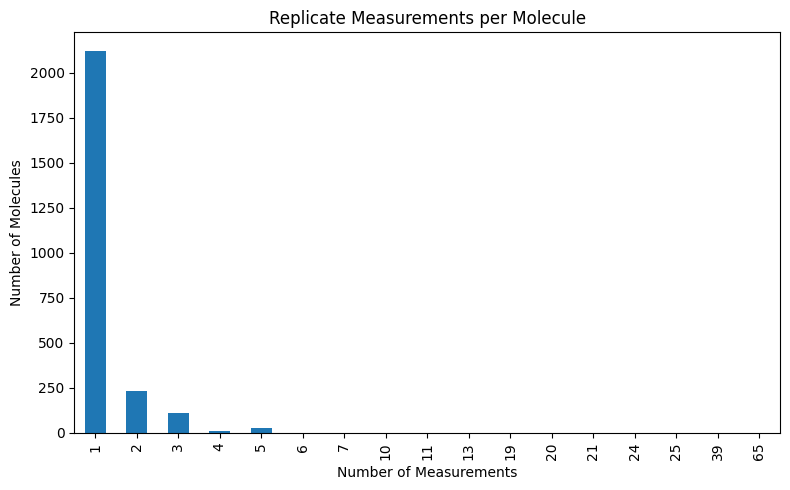

In [ ]:
# ==========================================================
# STEP 6.3 : Plot Replicate Distribution
# ==========================================================

plt.figure(figsize=(8,5))

replicate_distribution.plot(
    kind="bar"
)

plt.xlabel("Number of Measurements")

plt.ylabel("Number of Molecules")

plt.title("Replicate Measurements per Molecule")

plt.tight_layout()

plt.show()

In [ ]:
# ==========================================================
# STEP 6.4 : Convert IC50 to Numeric
# ==========================================================

activity["standard_value"] = pd.to_numeric(
    activity["standard_value"],
    errors="coerce"
)

print(activity["standard_value"].dtype)

float64


In [ ]:
#STEP 6.5

activity_unique = (
    activity
    .groupby("Canonical_SMILES", as_index=False)
    .agg(
        molecule_chembl_id=("molecule_chembl_id", "first"),
        Original_SMILES=("canonical_smiles", "first"),
        target_chembl_id=("target_chembl_id", "first"),
        standard_units=("standard_units", "first"),
        assay_type=("assay_type", "first"),
        assay_description=("assay_description", "first"),

        IC50_nM=("standard_value", "median"),
        Mean_IC50_nM=("standard_value", "mean"),
        Std_IC50_nM=("standard_value", "std"),
        Min_IC50_nM=("standard_value", "min"),
        Max_IC50_nM=("standard_value", "max"),
        Number_of_Assays=("standard_value", "count")
    )
)

activity_unique = activity_unique.round({
    "IC50_nM":4,
    "Mean_IC50_nM":4,
    "Std_IC50_nM":4,
    "Min_IC50_nM":4,
    "Max_IC50_nM":4
})

activity_unique = activity_unique[
    [
        "molecule_chembl_id",
        "Original_SMILES",
        "Canonical_SMILES",
        "IC50_nM",
        "Mean_IC50_nM",
        "Std_IC50_nM",
        "Min_IC50_nM",
        "Max_IC50_nM",
        "Number_of_Assays",
        "target_chembl_id",
        "standard_units",
        "assay_type",
        "assay_description"
    ]
]

In [ ]:
# ==========================================================
# STEP 6.6 : Verify Duplicate Removal
# ==========================================================

duplicates = activity_unique.duplicated(
    subset="Canonical_SMILES"
).sum()

print(f"Remaining duplicate molecules : {duplicates}")

Remaining duplicate molecules : 0


In [ ]:
# ==========================================================
# STEP 6.7 : Save Unique Dataset
# ==========================================================

activity_unique.to_csv(
    "Data/Clean/HER2_Unique_Molecules.csv",
    index=False
)

print("Unique dataset saved successfully.")

Unique dataset saved successfully.


In [ ]:
# ==========================================================
# STEP 6.8 : Save Unique Molecule Dataset
# ==========================================================
#
# Purpose:
# Save the unique HER2 dataset after duplicate aggregation.
#
# ==========================================================

activity_unique.to_csv(
    "Data/Clean/04_HER2_Unique.csv",
    index=False
)

print("Unique dataset saved successfully.")

Unique dataset saved successfully.


In [ ]:
# ==========================================================
# STEP 7.1 : Check IC50 Values
# ==========================================================

print("="*60)
print("IC50 Summary")
print("="*60)

print(activity_unique["IC50_nM"].describe())

print("\n")

print("Minimum IC50 :", activity_unique["IC50_nM"].min())

print("Maximum IC50 :", activity_unique["IC50_nM"].max())

IC50 Summary
count    2.515000e+03
mean     4.681486e+03
std      2.904335e+04
min      4.000000e-02
25%      2.700000e+01
50%      1.565000e+02
75%      1.400000e+03
max      1.100000e+06
Name: IC50_nM, dtype: float64


Minimum IC50 : 0.04
Maximum IC50 : 1100000.0


In [ ]:
# ==========================================================
# STEP 7.2 : Check Invalid IC50 Values
# ==========================================================

invalid = activity_unique[
    activity_unique["IC50_nM"] <= 0
]

print("="*60)
print("Invalid IC50 Values")
print("="*60)

print(f"Number of invalid values : {len(invalid)}")

if len(invalid) > 0:
    display(invalid)

Invalid IC50 Values
Number of invalid values : 0


In [ ]:
# ==========================================================
# STEP 7.3 : Convert IC50 (nM) to pIC50
# ==========================================================
#
# Formula:
# pIC50 = 9 - log10(IC50 in nM)
#
# ==========================================================

import numpy as np

activity_unique["pIC50"] = (
    9 - np.log10(activity_unique["IC50_nM"])
)

activity_unique["pIC50"] = activity_unique["pIC50"].round(4)

print("="*60)
print("pIC50 Conversion Completed")
print("="*60)

activity_unique[
    [
        "IC50_nM",
        "pIC50"
    ]
].head()

pIC50 Conversion Completed


,IC50_nM,pIC50
0,1280.0,5.8928
1,2320.0,5.6345
2,460.0,6.3372
3,180.0,6.7447
4,4800.0,5.3188


In [ ]:
# ==========================================================
# STEP 7.4 : Statistical Summary of pIC50
# ==========================================================
#
# Purpose:
# Calculate descriptive statistics for pIC50.
#
# ==========================================================

print("="*70)
print("pIC50 Summary Statistics")
print("="*70)

print(activity_unique["pIC50"].describe().round(4))

pIC50 Summary Statistics
count    2515.0000
mean        6.6790
std         1.1659
min         2.9586
25%         5.8539
50%         6.8055
75%         7.5686
max        10.3979
Name: pIC50, dtype: float64


In [ ]:
# ==========================================================
# STEP 7.5 : Check Missing Values
# ==========================================================

print("="*70)
print("Missing Values")
print("="*70)

missing = activity_unique.isnull().sum()

missing = missing[missing > 0]

if len(missing) == 0:
    print("No missing values found.")
else:
    print(missing)

Missing Values
Std_IC50_nM    2118
dtype: int64


In [ ]:
# ==========================================================
# STEP 7.6 : Finalize and Save the Curated HER2 Activity Dataset
# ==========================================================
#
# Purpose:
# Finalize the curated HER2 activity dataset before
# molecular descriptor generation.
#
# This step:
#   1. Handles missing standard deviation values
#   2. Reorders columns
#   3. Sorts compounds by pIC50
#   4. Resets the DataFrame index
#   5. Performs a final quality check
#   6. Saves the curated dataset
#
# Output:
# Data/Clean/05_HER2_pIC50.csv
#
# ==========================================================

# ----------------------------------------------------------
# 1. Replace missing standard deviation values
# ----------------------------------------------------------

activity_unique["Std_IC50_nM"] = (
    activity_unique["Std_IC50_nM"]
    .fillna(0)
)

# ----------------------------------------------------------
# 2. Reorder columns
# ----------------------------------------------------------

activity_unique = activity_unique[
    [
        "molecule_chembl_id",
        "Original_SMILES",
        "Canonical_SMILES",
        "IC50_nM",
        "pIC50",
        "Mean_IC50_nM",
        "Std_IC50_nM",
        "Min_IC50_nM",
        "Max_IC50_nM",
        "Number_of_Assays",
        "target_chembl_id",
        "standard_units",
        "assay_type",
        "assay_description"
    ]
]

# ----------------------------------------------------------
# 3. Sort by pIC50 (Highest potency first)
# ----------------------------------------------------------

activity_unique = activity_unique.sort_values(
    by="pIC50",
    ascending=False
)

# ----------------------------------------------------------
# 4. Reset index
# ----------------------------------------------------------

activity_unique.reset_index(
    drop=True,
    inplace=True
)

# ----------------------------------------------------------
# 5. Final quality control
# ----------------------------------------------------------

print("=" * 80)
print("FINAL DATASET QUALITY CHECK")
print("=" * 80)

print(f"Number of compounds        : {len(activity_unique):,}")

print(f"Number of columns          : {activity_unique.shape[1]}")

print(f"Duplicate molecules        : {activity_unique.duplicated(subset='Canonical_SMILES').sum()}")

print(f"Missing values             : {activity_unique.isnull().sum().sum()}")

print(f"Minimum pIC50              : {activity_unique['pIC50'].min():.4f}")

print(f"Maximum pIC50              : {activity_unique['pIC50'].max():.4f}")

print("=" * 80)

# ----------------------------------------------------------
# 6. Save dataset
# ----------------------------------------------------------

output_file = "Data/Clean/05_HER2_pIC50.csv"

activity_unique.to_csv(
    output_file,
    index=False
)

print(f"\nDataset successfully saved to:\n{output_file}")

# ----------------------------------------------------------
# 7. Display the first five compounds
# ----------------------------------------------------------

activity_unique.head()

FINAL DATASET QUALITY CHECK
Number of compounds        : 2,515
Number of columns          : 14
Duplicate molecules        : 0
Missing values             : 0
Minimum pIC50              : 2.9586
Maximum pIC50              : 10.3979

Dataset successfully saved to:
Data/Clean/05_HER2_pIC50.csv


,molecule_chembl_id,Original_SMILES,Canonical_SMILES,IC50_nM,pIC50,Mean_IC50_nM,Std_IC50_nM,Min_IC50_nM,Max_IC50_nM,Number_of_Assays,target_chembl_id,standard_units,assay_type,assay_description
0,CHEMBL6132997,COc1cc2c(Nc3ccc(Oc4ccn5ncnc5c4)c(C)c3)ncnc2cc1...,COc1cc2c(Nc3ccc(Oc4ccn5ncnc5c4)c(C)c3)ncnc2cc1...,0.04,10.3979,0.040,0.0000,0.04,0.04,1,CHEMBL1824,nM,B,Inhibition of HER2 (unknown origin)
1,CHEMBL941,Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc...,Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc...,0.06,10.2218,0.060,0.0000,0.06,0.06,1,CHEMBL1824,nM,B,Inhibition of HER2 (unknown origin) incubated ...
2,CHEMBL5221067,N#Cc1c(NC(=O)CNc2n[nH]c3ncccc23)sc2c1CCCC2,N#Cc1c(NC(=O)CNc2n[nH]c3ncccc23)sc2c1CCCC2,0.14,9.8539,0.140,0.0000,0.14,0.14,1,CHEMBL1824,nM,B,Inhibition of HER2 (unknown origin) incubated ...
3,CHEMBL5977738,Cc1ccc(S(=O)(=O)c2ccc(C3C(C(=O)c4ccccc4)=C(N)N...,Cc1ccc(S(=O)(=O)c2ccc(C3C(C(=O)c4ccccc4)=C(N)N...,0.34,9.4685,0.340,0.0000,0.34,0.34,1,CHEMBL1824,nM,B,In vitro kinase inhibition assay: An in vitro ...
4,CHEMBL5178703,CCOc1cc2ncnc(Nc3ccc(Oc4cc5nncn5cn4)c(C)c3)c2cc...,CCOc1cc2ncnc(Nc3ccc(Oc4cc5nncn5cn4)c(C)c3)c2cc...,0.43,9.3665,1.016,1.4017,0.16,3.51,5,CHEMBL1824,nM,B,Inhibition of wild type human GST-tagged HER2 ...


In [ ]:
# ==========================================================
# STEP 8.0 : Create Descriptor Workspace
# ==========================================================
#
# Purpose:
# Create folders required for descriptor generation.
#
# ==========================================================

import os

descriptor_folders = [

    "Descriptors",

    "Descriptors/Input",

    "Descriptors/Output",

    "Descriptors/Logs"

]

for folder in descriptor_folders:
    os.makedirs(folder, exist_ok=True)

print("="*70)
print("Descriptor Workspace Created Successfully")
print("="*70)

for folder in descriptor_folders:
    print(folder)

Descriptor Workspace Created Successfully
Descriptors
Descriptors/Input
Descriptors/Output
Descriptors/Logs


In [ ]:
# ==========================================================
# STEP 8.1 : Prepare PaDEL Input (.smi)
# ==========================================================

import pandas as pd

print("=" * 70)
print("STEP 8.1 : Prepare PaDEL Input (.smi)")
print("=" * 70)

# Select required columns
padel_input = activity_unique[
    ["Canonical_SMILES", "molecule_chembl_id"]
].copy()

# Rename columns for clarity
padel_input.columns = ["SMILES", "Compound_ID"]

# -----------------------------
# Quality Control
# -----------------------------
print(f"Total compounds           : {len(padel_input):,}")
print(f"Missing SMILES            : {padel_input['SMILES'].isna().sum()}")
print(f"Missing Compound IDs      : {padel_input['Compound_ID'].isna().sum()}")
print(f"Duplicate Compound IDs    : {padel_input['Compound_ID'].duplicated().sum()}")
print(f"Duplicate SMILES          : {padel_input['SMILES'].duplicated().sum()}")

# Preview
print("\nFirst five compounds:")
display(padel_input.head())

# -----------------------------
# Save as .smi
# -----------------------------
output_file = "Data/Clean/HER2_PaDEL_Input.smi"

padel_input.to_csv(
    output_file,
    sep="\t",
    header=False,
    index=False
)

print("\n" + "=" * 70)
print("PaDEL input file successfully created.")
print(f"Saved to : {output_file}")
print("=" * 70)

STEP 8.1 : Prepare PaDEL Input (.smi)
Total compounds           : 2,515
Missing SMILES            : 0
Missing Compound IDs      : 0
Duplicate Compound IDs    : 0
Duplicate SMILES          : 0

First five compounds:


,SMILES,Compound_ID
0,COc1cc2c(Nc3ccc(Oc4ccn5ncnc5c4)c(C)c3)ncnc2cc1...,CHEMBL6132997
1,Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc...,CHEMBL941
2,N#Cc1c(NC(=O)CNc2n[nH]c3ncccc23)sc2c1CCCC2,CHEMBL5221067
3,Cc1ccc(S(=O)(=O)c2ccc(C3C(C(=O)c4ccccc4)=C(N)N...,CHEMBL5977738
4,CCOc1cc2ncnc(Nc3ccc(Oc4cc5nncn5cn4)c(C)c3)c2cc...,CHEMBL5178703



PaDEL input file successfully created.
Saved to : Data/Clean/HER2_PaDEL_Input.smi


In [ ]:
# ==========================================================
# STEP 8.2 : Import PaDEL Descriptor Matrix
# ==========================================================

import pandas as pd

print("=" * 70)
print("STEP 8.2 : Import PaDEL Descriptor Matrix")
print("=" * 70)

# ----------------------------------------------------------
# Read PaDEL descriptor file
# ----------------------------------------------------------

padel_descriptors = pd.read_csv("PaDEL_descriptors.csv")

# ----------------------------------------------------------
# Basic information
# ----------------------------------------------------------

print(f"Number of compounds   : {padel_descriptors.shape[0]:,}")
print(f"Number of descriptors : {padel_descriptors.shape[1]-1:,}")
print(f"Dataset shape         : {padel_descriptors.shape}")

print("\nColumn names (First 10):")
print(list(padel_descriptors.columns[:10]))

print("\nFirst five rows:")
display(padel_descriptors.head())

# ----------------------------------------------------------
# Check missing values
# ----------------------------------------------------------

missing = padel_descriptors.isnull().sum().sum()

print("\nTotal missing values :", missing)

# ----------------------------------------------------------
# Check duplicate compound IDs
# ----------------------------------------------------------

compound_col = padel_descriptors.columns[0]

duplicates = padel_descriptors[compound_col].duplicated().sum()

print("Duplicate compound IDs :", duplicates)

print("\nCompound ID column :", compound_col)

print("=" * 70)
print("STEP 8.2 completed successfully.")
print("=" * 70)

STEP 8.2 : Import PaDEL Descriptor Matrix
Number of compounds   : 2,515
Number of descriptors : 1,444
Dataset shape         : (2515, 1445)

Column names (First 10):
['Name', 'nAcid', 'ALogP', 'ALogp2', 'AMR', 'apol', 'naAromAtom', 'nAromBond', 'nAtom', 'nHeavyAtom']

First five rows:


,Name,nAcid,ALogP,ALogp2,AMR,apol,naAromAtom,nAromBond,nAtom,nHeavyAtom,...,AMW,WTPT-1,WTPT-2,WTPT-3,WTPT-4,WTPT-5,WPATH,WPOL,XLogP,Zagreb
0,CHEMBL6132997,0,-4.0813,16.657010,122.0669,140.627615,31,33,122,67,...,7.454333,139.256569,2.078456,54.880177,19.369596,35.510581,33462,111,4.840,360
1,CHEMBL941,0,-0.2265,0.051302,51.2973,80.212583,24,25,68,37,...,7.253809,76.474722,2.066884,24.739841,2.574342,22.165499,5324,56,4.265,194
2,CHEMBL5221067,0,-1.3101,1.716362,47.7360,50.890688,14,15,41,25,...,8.588064,51.853182,2.074127,23.682851,2.553439,17.971327,1642,38,1.988,134
3,CHEMBL5977738,0,-0.0380,0.001444,74.4993,82.871790,18,18,68,38,...,7.738127,77.566977,2.041236,19.388842,10.179443,5.697937,4464,71,8.544,212
4,CHEMBL5178703,0,-0.4772,0.227720,65.3447,85.666790,25,27,73,43,...,7.989665,88.920518,2.067919,39.634849,8.663243,28.444256,7447,69,4.495,232



Total missing values : 3213
Duplicate compound IDs : 0

Compound ID column : Name
STEP 8.2 completed successfully.


In [ ]:
# ==========================================================
# STEP 9.1 : Merge PaDEL Descriptors with pIC50 Dataset
# ==========================================================

import pandas as pd

print("=" * 70)
print("STEP 9.1 : Merge PaDEL Descriptors with pIC50 Dataset")
print("=" * 70)

# ----------------------------------------------------------
# Prepare activity dataset
# ----------------------------------------------------------

activity = activity_unique.copy()

activity = activity.rename(
    columns={
        "molecule_chembl_id": "Name"
    }
)

# Keep only required columns
activity = activity[
    [
        "Name",
        "pIC50"
    ]
]

# ----------------------------------------------------------
# Merge
# ----------------------------------------------------------

merged_data = pd.merge(
    activity,
    padel_descriptors,
    on="Name",
    how="inner"
)

# ----------------------------------------------------------
# Summary
# ----------------------------------------------------------

print(f"Activity dataset shape     : {activity.shape}")
print(f"Descriptor dataset shape   : {padel_descriptors.shape}")
print(f"Merged dataset shape       : {merged_data.shape}")

print("\nMissing pIC50 values :", merged_data["pIC50"].isna().sum())

print("\nFirst five rows:")

display(merged_data.head())

print("=" * 70)
print("STEP 9.1 completed successfully.")
print("=" * 70)

STEP 9.1 : Merge PaDEL Descriptors with pIC50 Dataset
Activity dataset shape     : (2515, 2)
Descriptor dataset shape   : (2515, 1445)
Merged dataset shape       : (2515, 1446)

Missing pIC50 values : 0

First five rows:


,Name,pIC50,nAcid,ALogP,ALogp2,AMR,apol,naAromAtom,nAromBond,nAtom,...,AMW,WTPT-1,WTPT-2,WTPT-3,WTPT-4,WTPT-5,WPATH,WPOL,XLogP,Zagreb
0,CHEMBL6132997,10.3979,0,-4.0813,16.657010,122.0669,140.627615,31,33,122,...,7.454333,139.256569,2.078456,54.880177,19.369596,35.510581,33462,111,4.840,360
1,CHEMBL941,10.2218,0,-0.2265,0.051302,51.2973,80.212583,24,25,68,...,7.253809,76.474722,2.066884,24.739841,2.574342,22.165499,5324,56,4.265,194
2,CHEMBL5221067,9.8539,0,-1.3101,1.716362,47.7360,50.890688,14,15,41,...,8.588064,51.853182,2.074127,23.682851,2.553439,17.971327,1642,38,1.988,134
3,CHEMBL5977738,9.4685,0,-0.0380,0.001444,74.4993,82.871790,18,18,68,...,7.738127,77.566977,2.041236,19.388842,10.179443,5.697937,4464,71,8.544,212
4,CHEMBL5178703,9.3665,0,-0.4772,0.227720,65.3447,85.666790,25,27,73,...,7.989665,88.920518,2.067919,39.634849,8.663243,28.444256,7447,69,4.495,232


STEP 9.1 completed successfully.


In [ ]:
# ==========================================================
# STEP 9.2 : Descriptor Quality Assessment
# ==========================================================

import pandas as pd

print("=" * 70)
print("STEP 9.2 : Descriptor Quality Assessment")
print("=" * 70)

# ----------------------------------------------------------
# Descriptor matrix only
# ----------------------------------------------------------

X = merged_data.drop(columns=["Name", "pIC50"])

print(f"Total descriptors : {X.shape[1]:,}")

# ----------------------------------------------------------
# Missing values
# ----------------------------------------------------------

missing_count = X.isnull().sum()

missing_desc = missing_count[missing_count > 0]

print(f"\nDescriptors with missing values : {len(missing_desc):,}")

if len(missing_desc) > 0:
    display(
        missing_desc.sort_values(ascending=False).head(20)
    )

# ----------------------------------------------------------
# Constant descriptors
# ----------------------------------------------------------

constant_desc = X.columns[X.nunique() == 1]

print(f"\nConstant descriptors : {len(constant_desc):,}")

if len(constant_desc) > 0:
    print(list(constant_desc[:20]))

# ----------------------------------------------------------
# Duplicate descriptor names
# ----------------------------------------------------------

duplicate_columns = X.columns[X.columns.duplicated()]

print(f"\nDuplicate descriptor names : {len(duplicate_columns):,}")

# ----------------------------------------------------------
# Infinite values
# ----------------------------------------------------------

import numpy as np

inf_values = np.isinf(X).sum().sum()

print(f"\nInfinite values : {inf_values:,}")

# ----------------------------------------------------------
# Numeric descriptors
# ----------------------------------------------------------

numeric_columns = X.select_dtypes(include=np.number).shape[1]

print(f"\nNumeric descriptors : {numeric_columns:,}")

print("=" * 70)
print("STEP 9.2 completed successfully.")
print("=" * 70)

STEP 9.2 : Descriptor Quality Assessment
Total descriptors : 1,444

Descriptors with missing values : 63


,0
BCUTw-1l,51
BCUTw-1h,51
BCUTc-1l,51
BCUTc-1h,51
BCUTp-1l,51
BCUTp-1h,51
SCH-3,51
SCH-4,51
SCH-5,51
SCH-6,51



Constant descriptors : 216
['nBondsQ', 'nHsNH3p', 'nHssNH2p', 'nHmisc', 'nsLi', 'nssBe', 'nssssBem', 'nsBH2', 'nssBH', 'nssssBm', 'nddC', 'nsNH3p', 'nssNH2p', 'nddsN', 'naOm', 'nsSiH3', 'nssSiH2', 'nsssSiH', 'nssssSi', 'nsPH2']

Duplicate descriptor names : 0

Infinite values : 0

Numeric descriptors : 1,444
STEP 9.2 completed successfully.


In [ ]:
# ==========================================================
# STEP 9.3 : Remove Descriptors with Missing Values
# ==========================================================

print("=" * 70)
print("STEP 9.3 : Remove Descriptors with Missing Values")
print("=" * 70)

# ----------------------------------------------------------
# Count descriptors before removal
# ----------------------------------------------------------

before = merged_data.shape[1] - 2   # Excluding Name and pIC50

# Remove descriptor columns containing any missing values
merged_data = merged_data.dropna(axis=1)

after = merged_data.shape[1] - 2

removed = before - after

print(f"Descriptors before removal : {before:,}")
print(f"Descriptors removed        : {removed:,}")
print(f"Descriptors remaining      : {after:,}")

print("=" * 70)
print("STEP 9.3 completed successfully.")
print("=" * 70)

STEP 9.3 : Remove Descriptors with Missing Values
Descriptors before removal : 1,444
Descriptors removed        : 63
Descriptors remaining      : 1,381
STEP 9.3 completed successfully.


In [ ]:
# ==========================================================
# STEP 9.4 : Remove Constant Descriptors
# ==========================================================

from sklearn.feature_selection import VarianceThreshold

print("=" * 70)
print("STEP 9.4 : Remove Constant Descriptors")
print("=" * 70)

# Separate metadata and descriptors
metadata = merged_data[["Name", "pIC50"]]
X = merged_data.drop(columns=["Name", "pIC50"])

before = X.shape[1]

# Remove zero-variance descriptors
selector = VarianceThreshold(threshold=0)

X_filtered = selector.fit_transform(X)

selected_columns = X.columns[selector.get_support()]

X_filtered = pd.DataFrame(
    X_filtered,
    columns=selected_columns,
    index=merged_data.index
)

# Merge back
merged_data = pd.concat([metadata, X_filtered], axis=1)

after = X_filtered.shape[1]

removed = before - after

print(f"Descriptors before removal : {before:,}")
print(f"Descriptors removed        : {removed:,}")
print(f"Descriptors remaining      : {after:,}")

print("=" * 70)
print("STEP 9.4 completed successfully.")
print("=" * 70)

STEP 9.4 : Remove Constant Descriptors
Descriptors before removal : 1,381
Descriptors removed        : 216
Descriptors remaining      : 1,165
STEP 9.4 completed successfully.


In [ ]:
# ==========================================================
# STEP 9.5 : Remove Highly Correlated Descriptors
# ==========================================================

import numpy as np

print("=" * 70)
print("STEP 9.5 : Remove Highly Correlated Descriptors")
print("=" * 70)

# ----------------------------------------------------------
# Separate metadata and descriptors
# ----------------------------------------------------------

metadata = merged_data[["Name", "pIC50"]]

X = merged_data.drop(columns=["Name", "pIC50"])

before = X.shape[1]

# ----------------------------------------------------------
# Correlation matrix
# ----------------------------------------------------------

corr_matrix = X.corr().abs()

# Upper triangle
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Select descriptors to remove
to_drop = [
    column
    for column in upper.columns
    if any(upper[column] > 0.90)
]

# Remove descriptors
X_filtered = X.drop(columns=to_drop)

# Merge back
merged_data = pd.concat(
    [metadata, X_filtered],
    axis=1
)

after = X_filtered.shape[1]

removed = before - after

print(f"Correlation threshold     : 0.90")
print(f"Descriptors before        : {before:,}")
print(f"Descriptors removed       : {removed:,}")
print(f"Descriptors remaining     : {after:,}")

print("=" * 70)
print("STEP 9.5 completed successfully.")
print("=" * 70)

STEP 9.5 : Remove Highly Correlated Descriptors
Correlation threshold     : 0.90
Descriptors before        : 1,165
Descriptors removed       : 677
Descriptors remaining     : 488
STEP 9.5 completed successfully.


In [ ]:
# ==========================================================
# STEP 9.6 : Save Final Cleaned Dataset
# ==========================================================

output_file = "Data/Clean/HER2_PaDEL_Preprocessed.csv"

merged_data.to_csv(output_file, index=False)

print("=" * 70)
print("STEP 9.6 : Save Final Cleaned Dataset")
print("=" * 70)

print(f"Final dataset shape : {merged_data.shape}")
print(f"Saved to : {output_file}")

print("=" * 70)
print("STEP 9.6 completed successfully.")
print("=" * 70)

STEP 9.6 : Save Final Cleaned Dataset
Final dataset shape : (2515, 490)
Saved to : Data/Clean/HER2_PaDEL_Preprocessed.csv
STEP 9.6 completed successfully.


In [ ]:
# ==========================================================
# STEP 10.1 : Prepare Features and Target
# ==========================================================

print("=" * 70)
print("STEP 10.1 : Prepare Features and Target")
print("=" * 70)

# ----------------------------------------------------------
# Feature matrix
# ----------------------------------------------------------

X = merged_data.drop(columns=["Name", "pIC50"])

# ----------------------------------------------------------
# Target variable
# ----------------------------------------------------------

y = merged_data["pIC50"]

print(f"Feature matrix shape : {X.shape}")
print(f"Target vector shape  : {y.shape}")

print(f"\nNumber of compounds  : {len(y):,}")
print(f"Number of descriptors: {X.shape[1]:,}")

print("=" * 70)
print("STEP 10.1 completed successfully.")
print("=" * 70)

STEP 10.1 : Prepare Features and Target
Feature matrix shape : (2515, 488)
Target vector shape  : (2515,)

Number of compounds  : 2,515
Number of descriptors: 488
STEP 10.1 completed successfully.


In [ ]:
# ==========================================================
# STEP 10.2 : Train-Test Split
# ==========================================================

from sklearn.model_selection import train_test_split

print("=" * 70)
print("STEP 10.2 : Train-Test Split")
print("=" * 70)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print(f"Training samples : {X_train.shape[0]:,}")
print(f"Testing samples  : {X_test.shape[0]:,}")

print(f"\nTraining descriptors : {X_train.shape[1]:,}")
print(f"Testing descriptors  : {X_test.shape[1]:,}")

print("=" * 70)
print("STEP 10.2 completed successfully.")
print("=" * 70)

STEP 10.2 : Train-Test Split
Training samples : 2,012
Testing samples  : 503

Training descriptors : 488
Testing descriptors  : 488
STEP 10.2 completed successfully.


In [ ]:
!pip install -q optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 17.7 MB/s eta 0:00:00


In [ ]:
!pip install -q catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 5.4 MB/s eta 0:00:00


In [ ]:
# ==========================================================
# STEP 11.1 : Import Required Libraries
# ==========================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# Machine Learning Models
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

print("="*70)
print("STEP 11.1 : Libraries Imported Successfully")
print("="*70)

STEP 11.1 : Libraries Imported Successfully


In [ ]:
# Install required packages
!pip install -q catboost lightgbm xgboost

In [ ]:
# ==========================================================
# STEP 11.2 : Universal Model Evaluation Function
# ==========================================================

def evaluate_model(model, model_name,
                   X_train, X_test,
                   y_train, y_test):
    """
    Train, Cross-Validate and Evaluate a Regression Model
    """

    # -------------------------------
    # Train Model
    # -------------------------------
    model.fit(X_train, y_train)

    # -------------------------------
    # Predictions
    # -------------------------------
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # -------------------------------
    # Train Metrics
    # -------------------------------
    train_r2 = r2_score(y_train, train_pred)

    # -------------------------------
    # Test Metrics
    # -------------------------------
    test_r2 = r2_score(y_test, test_pred)

    mae = mean_absolute_error(y_test, test_pred)

    mse = mean_squared_error(y_test, test_pred)

    rmse = np.sqrt(mse)

    # -------------------------------
    # Cross Validation
    # -------------------------------
    cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="r2",
        n_jobs=-1
    )

    cv_mean = cv_scores.mean()

    cv_std = cv_scores.std()

    # -------------------------------
    # Train-Test Gap
    # -------------------------------
    gap = abs(train_r2 - test_r2)

    # -------------------------------
    # Return Results
    # -------------------------------
    return {
        "Model": model_name,
        "Train_R2": train_r2,
        "CV_Mean_R2": cv_mean,
        "CV_SD": cv_std,
        "Test_R2": test_r2,
        "MAE": mae,
        "RMSE": rmse,
        "MSE": mse,
        "Train_Test_Gap": gap
    }

print("="*70)
print("Universal Evaluation Function Created Successfully")
print("="*70)

Universal Evaluation Function Created Successfully


In [ ]:
# ==========================================================
# STEP 11.3 : Define Baseline Models
# ==========================================================

models = {

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=300,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1,
        verbosity=0
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=300,
        random_state=42,
        verbose=-1
    ),

    "CatBoost": CatBoostRegressor(
        iterations=300,
        random_seed=42,
        verbose=0
    )

}

print("="*70)
print(f"{len(models)} Baseline Models Loaded Successfully")
print("="*70)

5 Baseline Models Loaded Successfully


In [ ]:
# ==========================================================
# STEP 11.4 : Baseline Model Comparison
# ==========================================================

results = []

for name, model in models.items():

    print(f"Training {name}...")

    result = evaluate_model(
        model=model,
        model_name=name,
        X_train=X_train,
        X_test=X_test,
        y_train=y_train,
        y_test=y_test
    )

    results.append(result)

# ----------------------------------------------------------
# Results Table
# ----------------------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="CV_Mean_R2",
    ascending=False
).reset_index(drop=True)

# ----------------------------------------------------------
# Save Results
# ----------------------------------------------------------

results_df.to_csv(
    "Results/Baseline_Model_Comparison.csv",
    index=False
)

# ----------------------------------------------------------
# Display Results
# ----------------------------------------------------------

pd.set_option("display.precision", 4)

print("\n")
print("="*90)
print("BASELINE MODEL COMPARISON")
print("="*90)

display(results_df)

print("\nResults saved to:")
print("Results/Baseline_Model_Comparison.csv")

Training Random Forest...
Training Extra Trees...
Training XGBoost...
Training LightGBM...
Training CatBoost...


BASELINE MODEL COMPARISON


,Model,Train_R2,CV_Mean_R2,CV_SD,Test_R2,MAE,RMSE,MSE,Train_Test_Gap
0,Extra Trees,0.9939,0.6774,0.0312,0.7001,0.4632,0.6268,0.3928,0.2939
1,CatBoost,0.9594,0.6529,0.0380,0.6878,0.4820,0.6394,0.4089,0.2716
2,LightGBM,0.9937,0.6411,0.0361,0.6720,0.4856,0.6554,0.4296,0.3217
3,Random Forest,0.9485,0.6336,0.0251,0.6561,0.5083,0.6711,0.4504,0.2924
4,XGBoost,0.9939,0.6132,0.0242,0.6362,0.5228,0.6903,0.4765,0.3577



Results saved to:
Results/Baseline_Model_Comparison.csv


In [ ]:
# ==========================================================
# STEP 12.1 : Install and Import Optuna
# ==========================================================

!pip install -q optuna

import optuna
from optuna.samplers import TPESampler

print("="*70)
print("STEP 12.1 : Optuna Imported Successfully")
print("="*70)

STEP 12.1 : Optuna Imported Successfully


In [ ]:
# ==========================================================
# STEP 12.2 : Optuna Objective Function
# ==========================================================

import optuna
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import ExtraTreesRegressor

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

def objective(trial):

    model = ExtraTreesRegressor(

        n_estimators=trial.suggest_int(
            "n_estimators",
            100,
            400,
            step=50
        ),

        max_depth=trial.suggest_int(
            "max_depth",
            10,
            30
        ),

        min_samples_split=trial.suggest_int(
            "min_samples_split",
            2,
            10
        ),

        min_samples_leaf=trial.suggest_int(
            "min_samples_leaf",
            1,
            5
        ),

        max_features=trial.suggest_categorical(
            "max_features",
            ["sqrt", "log2", 0.5]
        ),

        bootstrap=trial.suggest_categorical(
            "bootstrap",
            [True, False]
        ),

        random_state=42,
        n_jobs=-1
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="r2",
        n_jobs=-1
    )

    return scores.mean()

In [ ]:
# ==========================================================
# STEP 12.3 : Hyperparameter Optimization
# ==========================================================

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(
    objective,
    n_trials=30,
    show_progress_bar=True
)

print("="*70)
print("Best CV R² :", study.best_value)
print("="*70)

print("\nBest Parameters:\n")

for k, v in study.best_params.items():
    print(f"{k:20s}: {v}")

[I 2026-07-22 16:52:58,553] A new study created in memory with name: no-name-06625137-c04c-4b34-ac6c-a65207416f20


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-07-22 16:53:07,707] Trial 0 finished with value: 0.6055176729335031 and parameters: {'n_estimators': 200, 'max_depth': 29, 'min_samples_split': 8, 'min_samples_leaf': 3, 'max_features': 'sqrt', 'bootstrap': True}. Best is trial 0 with value: 0.6055176729335031.
[I 2026-07-22 16:53:18,549] Trial 1 finished with value: 0.5633233855378307 and parameters: {'n_estimators': 300, 'max_depth': 10, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'bootstrap': False}. Best is trial 0 with value: 0.6055176729335031.
[I 2026-07-22 16:54:14,836] Trial 2 finished with value: 0.650844110995613 and parameters: {'n_estimators': 250, 'max_depth': 16, 'min_samples_split': 7, 'min_samples_leaf': 1, 'max_features': 0.5, 'bootstrap': True}. Best is trial 2 with value: 0.650844110995613.
[I 2026-07-22 16:54:45,948] Trial 3 finished with value: 0.6448723700356747 and parameters: {'n_estimators': 250, 'max_depth': 22, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features':

In [ ]:
# ==========================================================
# STEP 12.5 : Train Final Optimized Extra Trees Model
# ==========================================================

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
import numpy as np
import pandas as pd

# Build optimized model
final_model = ExtraTreesRegressor(
    **study.best_params,
    random_state=42,
    n_jobs=-1
)

# Train model
final_model.fit(X_train, y_train)

# Predictions
train_pred = final_model.predict(X_train)
test_pred = final_model.predict(X_test)

# Metrics
train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, test_pred)

mae = mean_absolute_error(y_test, test_pred)
mse = mean_squared_error(y_test, test_pred)
rmse = np.sqrt(mse)

gap = abs(train_r2 - test_r2)

# Results
final_results = pd.DataFrame({
    "Metric": [
        "Train R²",
        "Test R²",
        "MAE",
        "RMSE",
        "MSE",
        "Train-Test Gap"
    ],
    "Value": [
        train_r2,
        test_r2,
        mae,
        rmse,
        mse,
        gap
    ]
})

print("=" * 70)
print("FINAL OPTIMIZED EXTRA TREES MODEL")
print("=" * 70)

display(final_results)

final_results.to_csv(
    "Results/Final_Optimized_ExtraTrees_Performance.csv",
    index=False
)

print("\nResults saved successfully.")

FINAL OPTIMIZED EXTRA TREES MODEL


,Metric,Value
0,Train R²,0.9893
1,Test R²,0.7046
2,MAE,0.4633
3,RMSE,0.6220
4,MSE,0.3869
5,Train-Test Gap,0.2847



Results saved successfully.


In [ ]:
# ==========================================================
# STEP 13.1 : 5-Fold Cross Validation of Final Model
# ==========================================================

from sklearn.model_selection import KFold, cross_validate
import pandas as pd
import numpy as np

# ----------------------------------------------------------
# Cross Validation Strategy
# ----------------------------------------------------------

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ----------------------------------------------------------
# Multiple Evaluation Metrics
# ----------------------------------------------------------

scoring = {
    "R2": "r2",
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error"
}

# ----------------------------------------------------------
# Perform Cross Validation
# ----------------------------------------------------------

cv_results = cross_validate(
    estimator=final_model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

# ----------------------------------------------------------
# Summary Statistics
# ----------------------------------------------------------

r2_mean = np.mean(cv_results["test_R2"])
r2_sd = np.std(cv_results["test_R2"])

mae_mean = -np.mean(cv_results["test_MAE"])
mae_sd = np.std(-cv_results["test_MAE"])

rmse_mean = -np.mean(cv_results["test_RMSE"])
rmse_sd = np.std(-cv_results["test_RMSE"])

# ----------------------------------------------------------
# Create Results Table
# ----------------------------------------------------------

cv_summary = pd.DataFrame({

    "Metric":[
        "R²",
        "MAE",
        "RMSE"
    ],

    "Mean":[
        r2_mean,
        mae_mean,
        rmse_mean
    ],

    "SD":[
        r2_sd,
        mae_sd,
        rmse_sd
    ]

})

print("="*75)
print("STEP 13.1 : 5-FOLD CROSS VALIDATION RESULTS")
print("="*75)

display(cv_summary)

cv_summary.to_csv(
    "Results/5Fold_CrossValidation_Results.csv",
    index=False
)

print("\nResults saved successfully.")

STEP 13.1 : 5-FOLD CROSS VALIDATION RESULTS


,Metric,Mean,SD
0,R²,0.6796,0.0286
1,MAE,0.4858,0.0146
2,RMSE,0.6612,0.0262



Results saved successfully.


In [ ]:
# ==========================================================
# STEP 13.2 : Publication Summary
# ==========================================================

print("="*75)
print("Publication Ready Results")
print("="*75)

print(f"Cross Validation R²   : {r2_mean:.3f} ± {r2_sd:.3f}")
print(f"Cross Validation MAE  : {mae_mean:.3f} ± {mae_sd:.3f}")
print(f"Cross Validation RMSE : {rmse_mean:.3f} ± {rmse_sd:.3f}")

print("="*75)

Publication Ready Results
Cross Validation R²   : 0.680 ± 0.029
Cross Validation MAE  : 0.486 ± 0.015
Cross Validation RMSE : 0.661 ± 0.026


In [ ]:
# ==========================================================
# STEP 14.1 : Residual Analysis
# ==========================================================

import pandas as pd
import numpy as np

# ---------------------------------------------
# Predictions
# ---------------------------------------------

train_pred = final_model.predict(X_train)
test_pred = final_model.predict(X_test)

# ---------------------------------------------
# Residuals
# ---------------------------------------------

train_residual = y_train - train_pred
test_residual = y_test - test_pred

# ---------------------------------------------
# Save Results
# ---------------------------------------------

train_results = pd.DataFrame({
    "Experimental": y_train,
    "Predicted": train_pred,
    "Residual": train_residual
})

test_results = pd.DataFrame({
    "Experimental": y_test,
    "Predicted": test_pred,
    "Residual": test_residual
})

train_results.to_csv(
    "Results/Train_Residuals.csv",
    index=False
)

test_results.to_csv(
    "Results/Test_Residuals.csv",
    index=False
)

print("="*70)
print("Residuals calculated successfully.")
print("="*70)

Residuals calculated successfully.


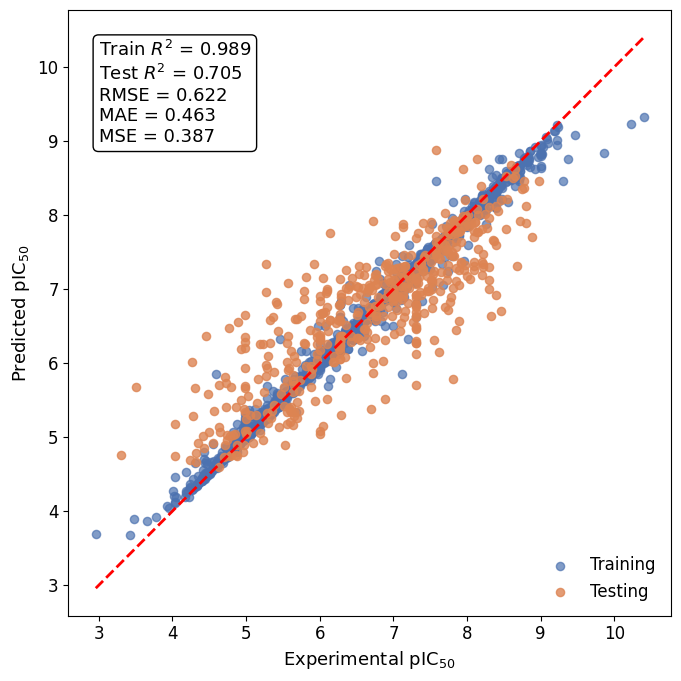

In [ ]:
# ==========================================================
# STEP 14.2 : Publication-Quality Experimental vs Predicted
# ==========================================================

import matplotlib.pyplot as plt
from matplotlib import rcParams

# -----------------------------
# Font settings
# -----------------------------
rcParams['font.family'] = 'Times New Roman'
rcParams['font.size'] = 13

# -----------------------------
# Figure
# -----------------------------
plt.figure(figsize=(7,7))

# Training
plt.scatter(
    y_train,
    train_pred,
    color="#4C72B0",
    alpha=0.70,
    s=35,
    label="Training"
)

# Testing
plt.scatter(
    y_test,
    test_pred,
    color="#DD8452",
    alpha=0.80,
    s=35,
    label="Testing"
)

# -----------------------------
# Identity line
# -----------------------------
minimum = min(min(y_train), min(y_test))
maximum = max(max(y_train), max(y_test))

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red",
    linestyle="--",
    linewidth=2
)

# -----------------------------
# Labels
# -----------------------------
plt.xlabel("Experimental pIC$_{50}$", fontsize=13)
plt.ylabel("Predicted pIC$_{50}$", fontsize=13)

# -----------------------------
# Metrics Box
# -----------------------------
metrics_text = (
    f"Train $R^2$ = {train_r2:.3f}\n"
    f"Test $R^2$ = {test_r2:.3f}\n"
    f"RMSE = {rmse:.3f}\n"
    f"MAE = {mae:.3f}\n"
    f"MSE = {mse:.3f}"
)

plt.text(
    0.05,
    0.95,
    metrics_text,
    transform=plt.gca().transAxes,
    fontsize=13,
    verticalalignment='top',
    bbox=dict(
        facecolor='white',
        edgecolor='black',
        boxstyle='round'
    )
)

# -----------------------------
# Legend
# -----------------------------
plt.legend(frameon=False, fontsize=12)

# -----------------------------
# Axis style
# -----------------------------
plt.tick_params(axis='both', labelsize=12)

plt.tight_layout()

plt.savefig(
    "Results/Figure_Experimental_vs_Predicted_Publication.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

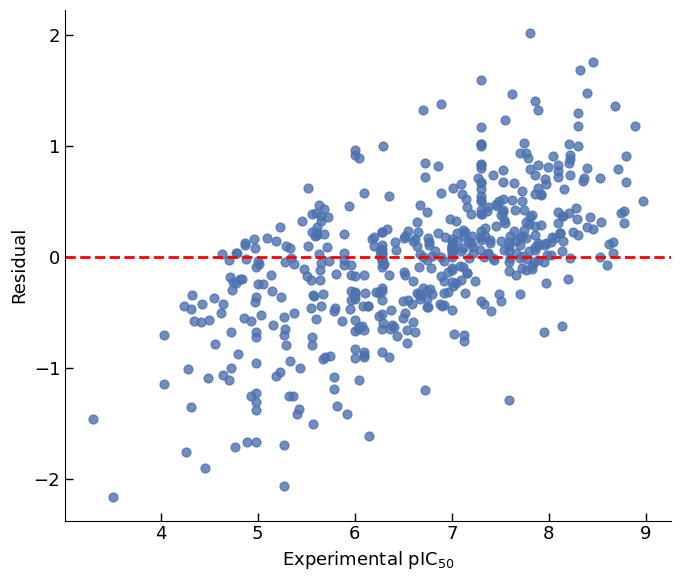

In [ ]:
# ==========================================================
# STEP 14.3 : Residuals vs Experimental pIC50
# ==========================================================

import matplotlib.pyplot as plt
from matplotlib import rcParams

# ----------------------------------------------------------
# Font settings
# ----------------------------------------------------------
rcParams["font.family"] = "Times New Roman"
rcParams["font.size"] = 13

# ----------------------------------------------------------
# Figure
# ----------------------------------------------------------
plt.figure(figsize=(7,6))

plt.scatter(
    y_test,
    test_residual,
    color="#4C72B0",
    alpha=0.80,
    s=40
)

# Zero residual line
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2
)

# Labels
plt.xlabel("Experimental pIC$_{50}$", fontsize=13)
plt.ylabel("Residual", fontsize=13)

# Axis style
plt.tick_params(direction="in", length=6, width=1)

# Remove top/right borders
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "Results/Figure_Residual_vs_Experimental.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

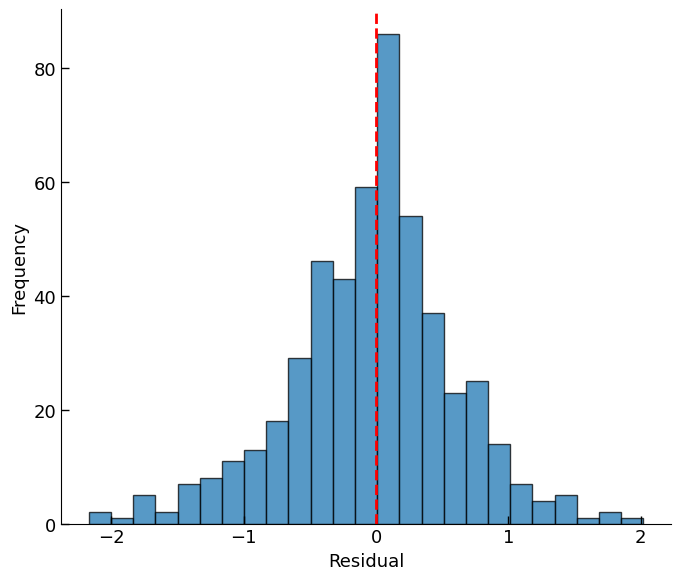

In [ ]:
# ==========================================================
# STEP 14.4 : Residual Distribution
# ==========================================================

plt.figure(figsize=(7,6))

plt.hist(
    test_residual,
    bins=25,
    edgecolor="black",
    linewidth=1.0,
    alpha=0.75
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    linewidth=2
)

plt.xlabel("Residual", fontsize=13)
plt.ylabel("Frequency", fontsize=13)

plt.tick_params(direction="in", length=6, width=1)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "Results/Figure_Residual_Distribution.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

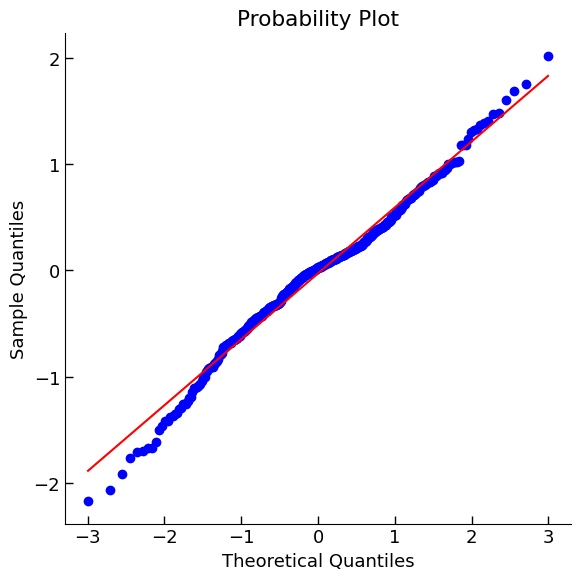

In [ ]:
# ==========================================================
# STEP 14.5 : Normal Q-Q Plot
# ==========================================================

import scipy.stats as stats

plt.figure(figsize=(6,6))

stats.probplot(
    test_residual,
    dist="norm",
    plot=plt
)

plt.xlabel("Theoretical Quantiles", fontsize=13)
plt.ylabel("Sample Quantiles", fontsize=13)

plt.tick_params(direction="in", length=6, width=1)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "Results/Figure_QQPlot.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ==========================================================
# STEP 14.6 : Calculate Standardized Residuals
# ==========================================================

import numpy as np
import pandas as pd

# ----------------------------------------------------------
# Calculate residuals
# ----------------------------------------------------------

train_residual = y_train - train_pred
test_residual = y_test - test_pred

# ----------------------------------------------------------
# Standard deviation of training residuals
# (Used for standardization)
# ----------------------------------------------------------

residual_std = np.std(train_residual, ddof=1)

# ----------------------------------------------------------
# Standardized residuals
# ----------------------------------------------------------

train_std_residual = train_residual / residual_std
test_std_residual = test_residual / residual_std

# ----------------------------------------------------------
# Save results
# ----------------------------------------------------------

train_std_df = pd.DataFrame({
    "Experimental": y_train,
    "Predicted": train_pred,
    "Residual": train_residual,
    "Standardized_Residual": train_std_residual
})

test_std_df = pd.DataFrame({
    "Experimental": y_test,
    "Predicted": test_pred,
    "Residual": test_residual,
    "Standardized_Residual": test_std_residual
})

train_std_df.to_csv(
    "Results/Training_Standardized_Residuals.csv",
    index=False
)

test_std_df.to_csv(
    "Results/Testing_Standardized_Residuals.csv",
    index=False
)

print("="*70)
print("Standardized residuals calculated successfully.")
print("="*70)

Standardized residuals calculated successfully.


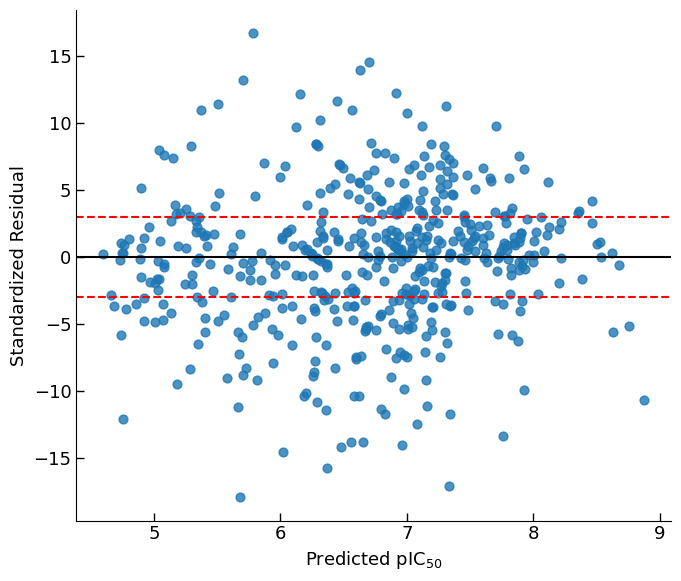

In [ ]:
# ==========================================================
# STEP 14.7 : Standardized Residual Plot
# ==========================================================

import matplotlib.pyplot as plt
from matplotlib import rcParams

# ----------------------------------------------------------
# Font settings
# ----------------------------------------------------------

rcParams["font.family"] = "Times New Roman"
rcParams["font.size"] = 13

# ----------------------------------------------------------
# Figure
# ----------------------------------------------------------

plt.figure(figsize=(7,6))

plt.scatter(
    test_pred,
    test_std_residual,
    color="#1f77b4",
    s=40,
    alpha=0.80
)

# Reference lines

plt.axhline(
    y=0,
    color="black",
    linewidth=1.5
)

plt.axhline(
    y=3,
    color="red",
    linestyle="--",
    linewidth=1.5
)

plt.axhline(
    y=-3,
    color="red",
    linestyle="--",
    linewidth=1.5
)

# Labels

plt.xlabel("Predicted pIC$_{50}$", fontsize=13)
plt.ylabel("Standardized Residual", fontsize=13)

# Style

plt.tick_params(direction="in", length=6, width=1)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "Results/Figure_Standardized_Residuals.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ==========================================================
# STEP 15.1 : Install SHAP
# ==========================================================

!pip install -q shap

import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("="*70)
print("SHAP Successfully Imported")
print("="*70)

SHAP Successfully Imported


In [ ]:
# ==========================================================
# STEP 15.2 : Create SHAP Explainer
# ==========================================================

# Create Tree Explainer
explainer = shap.TreeExplainer(final_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_train)

print("="*70)
print("SHAP values calculated successfully.")
print("="*70)

SHAP values calculated successfully.


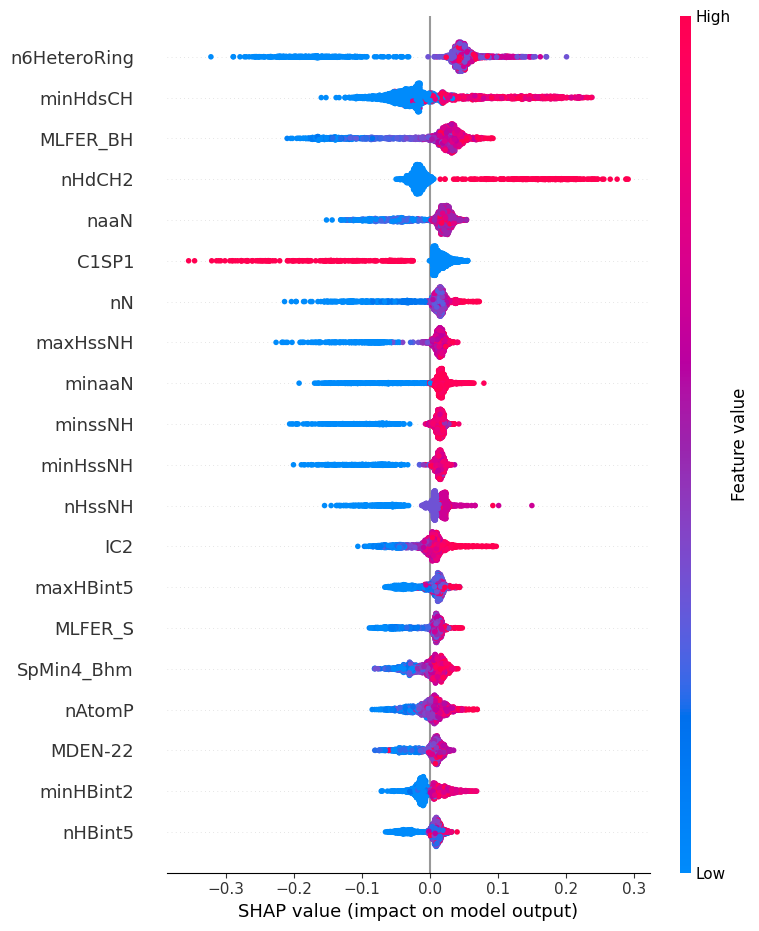

In [ ]:
# ==========================================================
# STEP 15.3 : SHAP Summary Plot
# ==========================================================

plt.figure(figsize=(8,6))

shap.summary_plot(
    shap_values,
    X_train,
    show=False,
    max_display=20
)

plt.tight_layout()

plt.savefig(
    "Results/Figure_SHAP_Summary.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

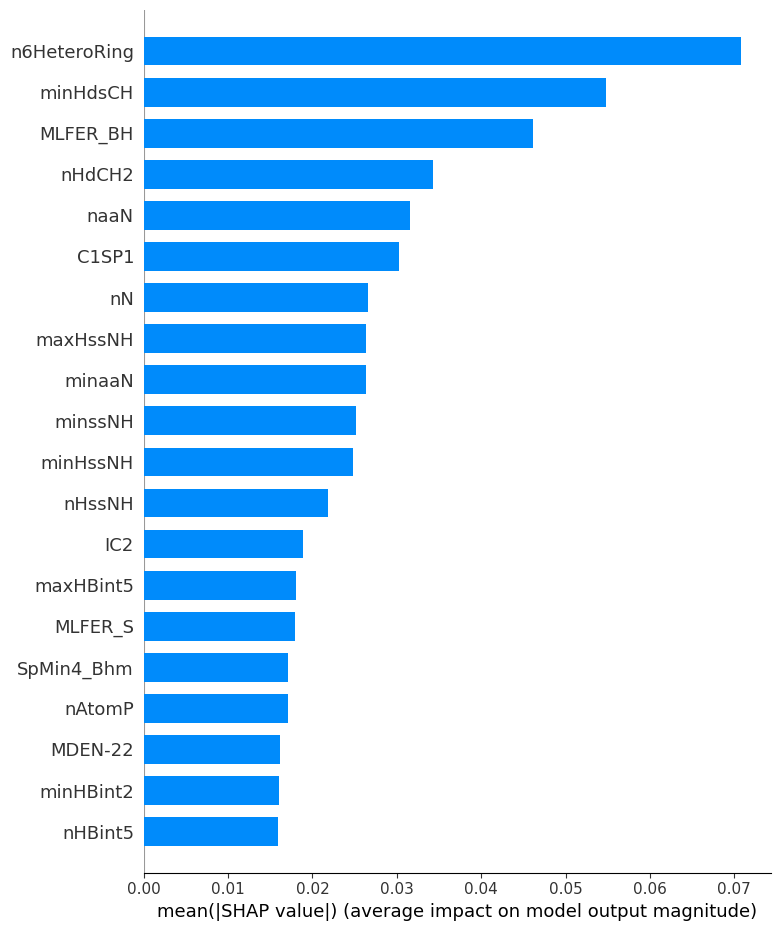

In [ ]:
# ==========================================================
# STEP 15.4 : SHAP Feature Importance
# ==========================================================

plt.figure(figsize=(8,6))

shap.summary_plot(
    shap_values,
    X_train,
    plot_type="bar",
    show=False,
    max_display=20
)

plt.tight_layout()

plt.savefig(
    "Results/Figure_SHAP_Bar.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ==========================================================
# STEP 15.5 : Export SHAP Importance
# ==========================================================

importance = np.abs(shap_values).mean(axis=0)

importance_df = pd.DataFrame({
    "Descriptor": X_train.columns,
    "Mean_SHAP": importance
})

importance_df = importance_df.sort_values(
    by="Mean_SHAP",
    ascending=False
)

importance_df.to_csv(
    "Results/SHAP_Descriptor_Importance.csv",
    index=False
)

print("="*70)
print("Top 20 SHAP descriptors")
print("="*70)

display(importance_df.head(20))

Top 20 SHAP descriptors


,Descriptor,Mean_SHAP
464,n6HeteroRing,0.0708
342,minHdsCH,0.0548
440,MLFER_BH,0.0461
284,nHdCH2,0.0343
298,naaN,0.0316
253,C1SP1,0.0302
7,nN,0.0265
374,maxHssNH,0.0264
356,minaaN,0.0263
354,minssNH,0.0252


In [ ]:
# ==========================================================
# STEP 16.1 : Y-Randomization (Y-Scrambling)
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.metrics import r2_score

n_iterations = 100
random_state = 42

rng = np.random.RandomState(random_state)

yr_results = []

for i in range(n_iterations):

    # Shuffle training labels
    y_train_random = rng.permutation(y_train)

    # Train model
    random_model = ExtraTreesRegressor(
        **study.best_params,
        random_state=42,
        n_jobs=-1
    )

    random_model.fit(X_train, y_train_random)

    # Predict
    y_pred_random = random_model.predict(X_test)

    # R²
    random_r2 = r2_score(y_test, y_pred_random)

    yr_results.append(random_r2)

print("Completed Y-randomization.")

Completed Y-randomization.


In [ ]:
# ==========================================================
# STEP 16.2 : Y-Randomization Summary
# ==========================================================

yr_df = pd.DataFrame({
    "Iteration": np.arange(1, n_iterations+1),
    "Random_R2": yr_results
})

yr_df.to_csv(
    "Results/Y_Randomization_Results.csv",
    index=False
)

summary = pd.DataFrame({
    "Metric":[
        "Original Test R²",
        "Random Mean R²",
        "Random SD"
    ],
    "Value":[
        test_r2,
        np.mean(yr_results),
        np.std(yr_results)
    ]
})

display(summary)

,Metric,Value
0,Original Test R²,0.7046
1,Random Mean R²,-0.1323
2,Random SD,0.0543


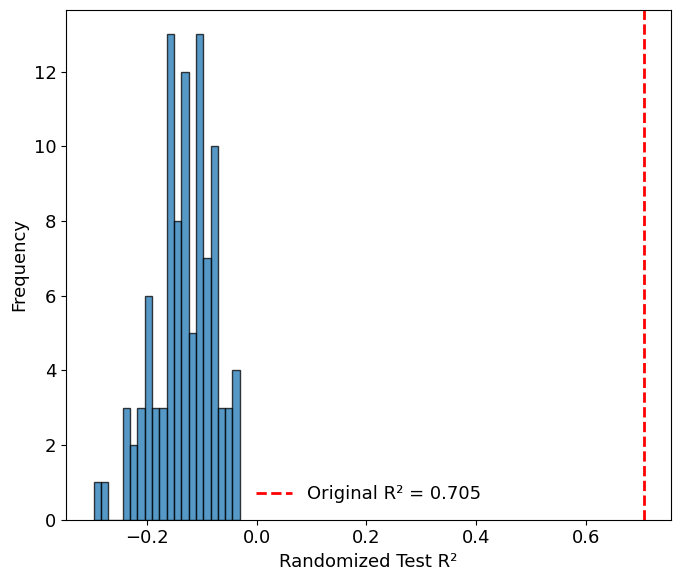

In [ ]:
# ==========================================================
# STEP 16.3 : Y-Randomization Plot
# ==========================================================

import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams["font.family"] = "Times New Roman"
rcParams["font.size"] = 13

plt.figure(figsize=(7,6))

plt.hist(
    yr_results,
    bins=20,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    test_r2,
    color="red",
    linewidth=2,
    linestyle="--",
    label=f"Original R² = {test_r2:.3f}"
)

plt.xlabel("Randomized Test R²")
plt.ylabel("Frequency")

plt.legend(frameon=False)

plt.tight_layout()

plt.savefig(
    "Results/Figure_Y_Randomization.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
type(X_train)

pandas.core.frame.DataFrame

In [ ]:
X_train.head()

,nAcid,ALogP,ALogp2,AMR,apol,naAromAtom,nB,nN,nO,nS,...,JGI6,JGI7,JGI8,JGI9,JGI10,VE1_D,VE3_D,TopoPSA,SRW5,XLogP
2461,0.0,0.1984,0.0394,50.2435,54.6347,12.0,0.0,2.0,1.0,1.0,...,0.0138,0.0121,0.0086,0.0072,0.0072,0.0935,-5.4505,67.59,0.0000,6.327
2284,0.0,0.5390,0.2905,53.1655,62.6599,16.0,0.0,3.0,5.0,0.0,...,0.0172,0.0156,0.0118,0.0087,0.0074,0.0152,-13.8149,83.96,3.0445,2.362
289,0.0,-1.1522,1.3276,52.5802,82.7914,27.0,0.0,6.0,4.0,0.0,...,0.0157,0.0121,0.0112,0.0071,0.0058,0.2148,-6.3053,134.28,2.3979,4.227
2031,0.0,0.9260,0.8575,51.4646,53.2907,12.0,0.0,3.0,1.0,1.0,...,0.0145,0.0126,0.0132,0.0129,0.0091,0.0920,-5.9647,70.33,3.0445,5.874
2254,0.0,-0.8773,0.7697,38.1057,61.1534,18.0,0.0,4.0,2.0,0.0,...,0.0201,0.0182,0.0111,0.0071,0.0062,0.2294,-4.2696,78.35,3.0445,4.102


In [ ]:
X_train.describe().T[['mean','std']].head(20)

,mean,std
nAcid,0.0169,0.1660
ALogP,-0.1850,1.2040
ALogp2,1.4832,2.6147
AMR,56.4834,23.3104
apol,71.2114,17.7010
naAromAtom,19.5626,5.8648
nB,0.0040,0.0629
nN,5.1257,1.9939
nO,2.7719,1.7519
nS,0.2639,0.5167


In [ ]:
# ==========================================================
# STEP 17.1 : Standardize Descriptor Space for AD
# ==========================================================

import numpy as np
from sklearn.preprocessing import StandardScaler

# ----------------------------------------------------------
# Fit scaler ONLY on the training descriptors
# ----------------------------------------------------------

scaler_ad = StandardScaler()

X_train_ad = scaler_ad.fit_transform(X_train)

X_test_ad = scaler_ad.transform(X_test)

print("=" * 70)
print("Descriptor space standardized successfully.")
print("=" * 70)

print(f"Training shape : {X_train_ad.shape}")
print(f"Testing shape  : {X_test_ad.shape}")

print("\nMean of first descriptor :", round(X_train_ad[:,0].mean(),4))
print("Std of first descriptor  :", round(X_train_ad[:,0].std(),4))

Descriptor space standardized successfully.
Training shape : (2012, 488)
Testing shape  : (503, 488)

Mean of first descriptor : -0.0
Std of first descriptor  : 1.0


In [ ]:
# ==========================================================
# STEP 17.2 : Build kNN Applicability Domain
# ==========================================================

from sklearn.neighbors import NearestNeighbors

# Number of neighbors
k = 5

knn = NearestNeighbors(
    n_neighbors=k,
    metric="euclidean"
)

knn.fit(X_train_ad)

print("=" * 70)
print("kNN Applicability Domain model created.")
print(f"Number of neighbors (k): {k}")
print("=" * 70)

kNN Applicability Domain model created.
Number of neighbors (k): 5


In [ ]:
# ==========================================================
# STEP 17.3 : Calculate kNN Distances
# ==========================================================

import numpy as np

# ----------------------------------------------------------
# Training compounds
# ----------------------------------------------------------

train_distances, train_indices = knn.kneighbors(X_train_ad)

# Ignore self-distance (0.0)
train_mean_distance = train_distances[:, 1:].mean(axis=1)

# ----------------------------------------------------------
# Test compounds
# ----------------------------------------------------------

test_distances, test_indices = knn.kneighbors(X_test_ad)

test_mean_distance = test_distances.mean(axis=1)

# ----------------------------------------------------------
# Summary
# ----------------------------------------------------------

print("=" * 70)
print("kNN distances calculated successfully.")
print("=" * 70)

print(f"Training compounds : {len(train_mean_distance)}")
print(f"Testing compounds  : {len(test_mean_distance)}")

print("\nTraining distance statistics")
print(f"Mean   : {train_mean_distance.mean():.4f}")
print(f"Median : {np.median(train_mean_distance):.4f}")
print(f"Std    : {train_mean_distance.std():.4f}")

print("\nTesting distance statistics")
print(f"Mean   : {test_mean_distance.mean():.4f}")
print(f"Median : {np.median(test_mean_distance):.4f}")
print(f"Std    : {test_mean_distance.std():.4f}")

kNN distances calculated successfully.
Training compounds : 2012
Testing compounds  : 503

Training distance statistics
Mean   : 11.7353
Median : 10.1436
Std    : 7.0130

Testing distance statistics
Mean   : 11.9600
Median : 10.7639
Std    : 6.4510


In [ ]:
# ==========================================================
# STEP 17.4 : Define Applicability Domain Threshold
# ==========================================================

# 95th percentile threshold based ONLY on training compounds
ad_threshold = np.percentile(train_mean_distance, 95)

print("=" * 70)
print("Applicability Domain Threshold")
print("=" * 70)

print(f"95th Percentile Threshold : {ad_threshold:.4f}")

Applicability Domain Threshold
95th Percentile Threshold : 22.5980


In [ ]:
# ==========================================================
# STEP 17.5 : Classify Compounds into AD
# ==========================================================

# Training compounds
train_ad_status = np.where(
    train_mean_distance <= ad_threshold,
    "Inside AD",
    "Outside AD"
)

# Test compounds
test_ad_status = np.where(
    test_mean_distance <= ad_threshold,
    "Inside AD",
    "Outside AD"
)

# ----------------------------------------------------------
# Count compounds
# ----------------------------------------------------------

train_inside = np.sum(train_ad_status == "Inside AD")
train_outside = np.sum(train_ad_status == "Outside AD")

test_inside = np.sum(test_ad_status == "Inside AD")
test_outside = np.sum(test_ad_status == "Outside AD")

# ----------------------------------------------------------
# Percentages
# ----------------------------------------------------------

train_inside_pct = train_inside / len(train_ad_status) * 100
test_inside_pct = test_inside / len(test_ad_status) * 100

# ----------------------------------------------------------
# Display results
# ----------------------------------------------------------

print("="*70)
print("kNN Applicability Domain Summary")
print("="*70)

print("\nTraining Set")
print(f"Inside AD  : {train_inside}")
print(f"Outside AD : {train_outside}")
print(f"Inside (%) : {train_inside_pct:.2f}%")

print("\nTesting Set")
print(f"Inside AD  : {test_inside}")
print(f"Outside AD : {test_outside}")
print(f"Inside (%) : {test_inside_pct:.2f}%")

kNN Applicability Domain Summary

Training Set
Inside AD  : 1911
Outside AD : 101
Inside (%) : 94.98%

Testing Set
Inside AD  : 479
Outside AD : 24
Inside (%) : 95.23%


In [ ]:
# ==========================================================
# STEP 17.6 : Export kNN Applicability Domain Results
# ==========================================================

import os
import pandas as pd

# ----------------------------------------------------------
# Generate predictions
# ----------------------------------------------------------

train_predictions = final_model.predict(X_train)
test_predictions = final_model.predict(X_test)

# ----------------------------------------------------------
# Create Results folder
# ----------------------------------------------------------

os.makedirs("Results", exist_ok=True)

# ----------------------------------------------------------
# Training AD DataFrame
# ----------------------------------------------------------

train_ad_df = pd.DataFrame({
    "Observed_pIC50": y_train.values,
    "Predicted_pIC50": train_predictions,
    "Mean_kNN_Distance": train_mean_distance,
    "AD_Status": train_ad_status
})

# ----------------------------------------------------------
# Testing AD DataFrame
# ----------------------------------------------------------

test_ad_df = pd.DataFrame({
    "Observed_pIC50": y_test.values,
    "Predicted_pIC50": test_predictions,
    "Mean_kNN_Distance": test_mean_distance,
    "AD_Status": test_ad_status
})

# ----------------------------------------------------------
# Save CSV files
# ----------------------------------------------------------

train_ad_df.to_csv(
    "Results/Training_kNN_Applicability_Domain.csv",
    index=False
)

test_ad_df.to_csv(
    "Results/Testing_kNN_Applicability_Domain.csv",
    index=False
)

# ----------------------------------------------------------
# Display summary
# ----------------------------------------------------------

print("="*70)
print("kNN Applicability Domain Results Exported Successfully")
print("="*70)

print(f"\nTraining compounds : {len(train_ad_df)}")
print(f"Testing compounds  : {len(test_ad_df)}")

print(f"\nTraining Inside AD : {(train_ad_status=='Inside AD').sum()}")
print(f"Training Outside AD: {(train_ad_status=='Outside AD').sum()}")

print(f"\nTesting Inside AD  : {(test_ad_status=='Inside AD').sum()}")
print(f"Testing Outside AD : {(test_ad_status=='Outside AD').sum()}")

print("\nFiles saved:")
print("Results/Training_kNN_Applicability_Domain.csv")
print("Results/Testing_kNN_Applicability_Domain.csv")

kNN Applicability Domain Results Exported Successfully

Training compounds : 2012
Testing compounds  : 503

Training Inside AD : 1911
Training Outside AD: 101

Testing Inside AD  : 479
Testing Outside AD : 24

Files saved:
Results/Training_kNN_Applicability_Domain.csv
Results/Testing_kNN_Applicability_Domain.csv


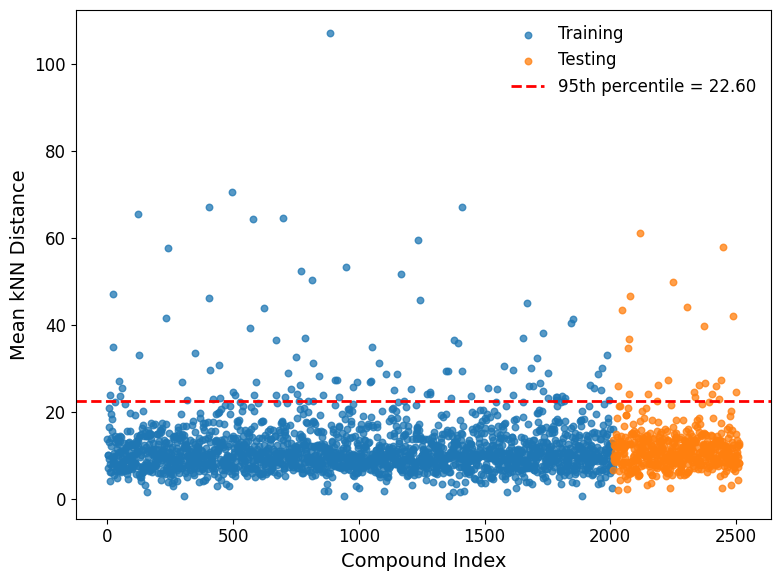

Figure saved successfully.
Results/Figure_kNN_Applicability_Domain.png


In [ ]:
# ==========================================================
# STEP 17.7 : Publication-quality kNN Applicability Domain Plot
# ==========================================================

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["font.family"] = "Times New Roman"

fig, ax = plt.subplots(figsize=(8,6))

# ----------------------------------------------------------
# Training compounds
# ----------------------------------------------------------

ax.scatter(
    np.arange(len(train_mean_distance)),
    train_mean_distance,
    s=22,
    alpha=0.75,
    label="Training",
)

# ----------------------------------------------------------
# Testing compounds
# ----------------------------------------------------------

ax.scatter(
    np.arange(len(train_mean_distance),
              len(train_mean_distance)+len(test_mean_distance)),
    test_mean_distance,
    s=22,
    alpha=0.75,
    label="Testing",
)

# ----------------------------------------------------------
# Threshold
# ----------------------------------------------------------

ax.axhline(
    ad_threshold,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"95th percentile = {ad_threshold:.2f}"
)

# ----------------------------------------------------------
# Labels
# ----------------------------------------------------------

ax.set_xlabel("Compound Index", fontsize=14)
ax.set_ylabel("Mean kNN Distance", fontsize=14)

ax.tick_params(labelsize=12)

ax.legend(frameon=False, fontsize=12)

plt.tight_layout()

plt.savefig(
    "Results/Figure_kNN_Applicability_Domain.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("="*70)
print("Figure saved successfully.")
print("="*70)
print("Results/Figure_kNN_Applicability_Domain.png")

In [ ]:
# ==========================================================
# STEP 18.1 : Create .smi file for Galaxy PaDEL
# ==========================================================

import pandas as pd

# Load phytochemicals
phyto_df = pd.read_csv("Phytochemicals.csv")

# Check first rows
display(phyto_df.head())

# Create compound IDs
phyto_df["Name"] = ["Phyto_" + str(i+1) for i in range(len(phyto_df))]

# Create SMI dataframe
smi_df = phyto_df[["Canonical_SMILES", "Name"]]

# Save as tab-separated .smi
smi_df.to_csv(
    "phytochemicals.smi",
    sep="\t",
    header=False,
    index=False
)

print("SMI file created successfully!")
print("File name: phytochemicals.smi")

,Canonical_SMILES
0,C1(O\C(=C/Br)\C(Br)=C1[C@H](OC(C)=O)CCC)=O
1,C1(O\C(=C\Br)\C(Br)=C1[C@H](OC(C)=O)CCC)=O
2,[C@@H]1(OC(=O)C(C)=C(Cl)C1)\C(\C)=C/Cl
3,CC([C@@]([H])([C@@]([H])([C@]([H])([C@](O)(C1)...
4,C1(OC(O)C=C1CCC2C(C=CCC2(C)C)=C)=C


SMI file created successfully!
File name: phytochemicals.smi


In [ ]:
#STEP 18.2 import pandas as pd

phyto_desc = pd.read_csv("PaDEL_phytochemicals.csv")

print("Shape:", phyto_desc.shape)
display(phyto_desc.head())

Shape: (20, 1445)


,Name,nAcid,ALogP,ALogp2,AMR,apol,naAromAtom,nAromBond,nAtom,nHeavyAtom,...,AMW,WTPT-1,WTPT-2,WTPT-3,WTPT-4,WTPT-5,WPATH,WPOL,XLogP,Zagreb
0,Phyto_1,0,0.3770,0.1421,66.8548,36.6695,0,0,29,17,...,12.6176,32.9061,1.9357,15.9111,10.8989,0.0,507,24,3.649,80
1,Phyto_2,0,0.3770,0.1421,66.8548,36.6695,0,0,29,17,...,12.6176,32.9061,1.9357,15.9111,10.8989,0.0,507,24,3.649,80
2,Phyto_3,0,2.6057,6.7897,52.6890,28.4719,0,0,23,13,...,9.5655,25.0770,1.9290,10.4318,5.5107,0.0,240,19,2.172,62
3,Phyto_4,0,0.2445,0.0598,66.2456,45.3406,0,0,43,17,...,5.5394,33.6263,1.9780,4.9171,4.9171,0.0,452,29,3.260,92
4,Phyto_5,0,2.4529,6.0167,76.6565,44.4334,0,0,40,18,...,6.1540,35.7026,1.9835,5.4659,5.4659,0.0,617,26,4.903,94


In [ ]:
#STEP 18.3
compound_names = phyto_desc["Name"]

phyto_desc = phyto_desc.drop(columns=["Name"])

In [ ]:
#STEP 18.4
phyto_desc = phyto_desc[X.columns]

print("Prediction dataset shape:", phyto_desc.shape)

Prediction dataset shape: (20, 488)


In [ ]:
#STEP 18.5
print("Missing values:", phyto_desc.isnull().sum().sum())

Missing values: 0


In [ ]:
#STEP 18.6
predicted_pIC50 = final_model.predict(phyto_desc)

print(predicted_pIC50)

[4.99780346 4.99780346 5.08376108 4.93949425 5.31375171 4.9799055
 5.16415696 5.09247158 5.00204112 4.88103996 5.36373421 4.97210096
 5.02003204 5.17793617 5.376911   5.11130367 5.06976633 5.15590158
 4.94561042 5.61615908]


In [ ]:
#STEP 18.7
prediction_results = pd.DataFrame({
    "Compound": compound_names,
    "Predicted_pIC50": predicted_pIC50
})

prediction_results = prediction_results.sort_values(
    by="Predicted_pIC50",
    ascending=False
)

prediction_results["Rank"] = range(1, len(prediction_results)+1)

prediction_results = prediction_results[
    ["Rank", "Compound", "Predicted_pIC50"]
]

prediction_results.reset_index(drop=True, inplace=True)

display(prediction_results)

,Rank,Compound,Predicted_pIC50
0,1,Phyto_20,5.6162
1,2,Phyto_15,5.3769
2,3,Phyto_11,5.3637
3,4,Phyto_5,5.3138
4,5,Phyto_14,5.1779
5,6,Phyto_7,5.1642
6,7,Phyto_18,5.1559
7,8,Phyto_16,5.1113
8,9,Phyto_8,5.0925
9,10,Phyto_3,5.0838


In [ ]:
#STEP 18.8
phyto_scaled = scaler_ad.transform(phyto_desc)

phyto_distances, _ = knn.kneighbors(phyto_scaled)

phyto_mean_distance = phyto_distances.mean(axis=1)

phyto_ad_status = [
    "Inside AD" if d <= ad_threshold else "Outside AD"
    for d in phyto_mean_distance
]

prediction_results["Mean_kNN_Distance"] = phyto_mean_distance
prediction_results["AD_Status"] = phyto_ad_status

display(prediction_results)

,Rank,Compound,Predicted_pIC50,Mean_kNN_Distance,AD_Status
0,1,Phyto_20,5.6162,43.8681,Outside AD
1,2,Phyto_15,5.3769,43.8681,Outside AD
2,3,Phyto_11,5.3637,44.9172,Outside AD
3,4,Phyto_5,5.3138,43.8026,Outside AD
4,5,Phyto_14,5.1779,40.4355,Outside AD
5,6,Phyto_7,5.1642,104.2691,Outside AD
6,7,Phyto_18,5.1559,159.2104,Outside AD
7,8,Phyto_16,5.1113,85.9230,Outside AD
8,9,Phyto_8,5.0925,92.1233,Outside AD
9,10,Phyto_3,5.0838,72.7070,Outside AD


In [ ]:
#STEP 18.9
prediction_results.to_excel(
    "Predictions/Predicted_pIC50_with_AD.xlsx",
    index=False
)

prediction_results.to_csv(
    "Predictions/Predicted_pIC50_with_AD.csv",
    index=False
)

print("Prediction completed successfully!")

Prediction completed successfully!


In [ ]:
print(X_train.equals(X.loc[X_train.index]))
print(list(X_train.columns) == list(X.columns))

True
True


In [ ]:
print(all(phyto_desc.columns == X_train.columns))

True


In [ ]:
comparison = pd.DataFrame({
    "Training": X_train.columns[:20],
    "Phytochemicals": phyto_desc.columns[:20]
})

display(comparison)

,Training,Phytochemicals
0,nAcid,nAcid
1,ALogP,ALogP
2,ALogp2,ALogp2
3,AMR,AMR
4,apol,apol
5,naAromAtom,naAromAtom
6,nB,nB
7,nN,nN
8,nO,nO
9,nS,nS


In [ ]:
comparison = pd.DataFrame({
    "Training_mean": X_train.mean(),
    "Phyto_mean": phyto_desc.mean()
})

comparison["Difference"] = (
    comparison["Training_mean"] -
    comparison["Phyto_mean"]
).abs()

comparison.sort_values(
    "Difference",
    ascending=False
).head(20)

,Training_mean,Phyto_mean,Difference
ATS0m,7488.7347,12584.2158,5095.4811
ATSC5m,-29.3617,-3160.4243,3131.0626
VR1_DzZ,2732.8311,141.7195,2591.1116
ATSC4m,-76.4156,1685.0393,1761.4550
ATSC5v,359.3811,-553.6200,913.0011
ATSC7m,-77.5031,-977.7632,900.2601
ATSC6m,68.3262,-659.7810,728.1072
AATS0m,134.0491,658.1185,524.0693
VR1_Dzs,725.2988,272.9909,452.3079
ATSC3m,-266.6568,-655.0664,388.4095
